# 04 — Comprendre les performances et tester les sensibilités

Investigation demandée après le benchmark 03, sur la branche `task/salh-supervised-training`.
Quatre cibles séparées ; COREG reste différé. **Le protocole externe reste identique.**
Les analyses sont rétrospectives : une amélioration constatée ici ne constitue pas
une validation sur un nouveau dataset indépendant. Le but est de comprendre les
limites, sans garantir R² ≥ 0,5 ni retirer les observations difficiles.

La méthode précède chaque section. Les décisions sont dans `specs/spec.md`,
les exports ignorés sous `data/processed/experiments/salh_diagnostics_v1/`.
Aucune cible n'est imputée ; dureté et FATT50 restent exclus des entrées et sorties.

In [2]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import platform
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import joblib
from IPython.display import display
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.exceptions import ConvergenceWarning
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer, SimpleImputer
from sklearn.linear_model import BayesianRidge, Ridge
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, ParameterGrid
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from joblib import Memory, parallel_config
from threadpoolctl import threadpool_limits

SEED = 42
N_JOBS = 3  # recherches parallèles ; chaque forêt utilise un seul worker
PRIMARY_SET = 'A1_13'
PRIMARY_IMPUTER = 'iterative'
TARGETS = ['yield_strength', 'uts', 'elongation', 'charpy_J']
CAT = 'weld_process'
PROCESS_COL = CAT
CORE13 = ['C', 'Si', 'Mn', 'S', 'P', 'current_A', 'voltage_V',
          'heat_input_kJmm', 'interpass_C', 'pwht_temp_C', 'pwht_time_h',
          'O_ppm', 'N_ppm']
NONNEG = CORE13  # la température d'essai Charpy peut être négative
TARGET_UNITS = {'yield_strength': 'MPa', 'uts': 'MPa',
                'elongation': 'points de %', 'charpy_J': 'J'}
TARGET_NAMES = {'yield_strength': "Limite d'élasticité", 'uts': 'Résistance maximale',
                'elongation': 'Allongement', 'charpy_J': 'Énergie Charpy — exploratoire'}
MODEL_NAMES = {'median_y': 'Médiane de y', 'ridge': 'Ridge', 'svr_rbf': 'SVR RBF',
               'random_forest': 'Random Forest', 'knn': 'kNN'}
PARAM_GRIDS = {
    'median_y': {},
    'ridge': {'model__alpha': [0.01, 0.1, 1, 10, 100, 1000]},
    'svr_rbf': {'model__regressor__C': [1, 10, 100],
                'model__regressor__gamma': ['scale', 0.05],
                'model__regressor__epsilon': [0.05, 0.2]},
    'random_forest': {'model__min_samples_leaf': [1, 2, 5],
                     'model__max_depth': [None, 10],
                     'model__max_features': [0.5, 1.0]},
    'knn': {'model__n_neighbors': [3, 5, 9, 15], 'model__p': [1, 2]},
}

def numeric_features(target):
    if target not in TARGETS:
        raise ValueError(f'Cible non prévue : {target}')
    return list(CORE13) + (['charpy_temp_C'] if target == 'charpy_J' else [])

def task_features(target):
    return numeric_features(target) + [CAT]

def eligible_rows(frame, target):
    # La température d'essai est une condition connue pour E(T), jamais imputée
    # pour fabriquer un couple Charpy dont la condition d'essai serait inconnue.
    mask = frame['in_strict13'] & frame[target].notna()
    if target == 'charpy_J':
        mask &= frame.charpy_temp_C.notna()
    return frame.loc[mask].copy()

def outer_partitions(frame, target, outer_fold):
    eligible = eligible_rows(frame, target)
    train = eligible.loc[eligible.outer_fold != outer_fold].reset_index(drop=True)
    valid = eligible.loc[eligible.outer_fold == outer_fold].reset_index(drop=True)
    if train.empty or valid.empty:
        raise ValueError(f'Partition vide : {target}, pli {outer_fold}')
    if not set(train.group).isdisjoint(valid.group):
        raise AssertionError('Un groupe externe est partagé entre train et validation.')
    return train, valid

def inner_splits(train, outer_fold):
    col = f'inner_fold_when_outer{outer_fold}'
    if not set(train[col].unique()).issubset({0, 1, 2}):
        raise AssertionError('Les lignes externes ne doivent pas entrer dans les plis internes.')
    splits = []
    for inner_fold in range(3):
        tr = np.flatnonzero(train[col].to_numpy() != inner_fold)
        va = np.flatnonzero(train[col].to_numpy() == inner_fold)
        if len(tr) < 15 or len(va) < 2:
            raise ValueError('Effectif interne insuffisant pour les grilles prévues.')
        if not set(train.iloc[tr].group).isdisjoint(train.iloc[va].group):
            raise AssertionError('Un groupe interne est partagé.')
        splits.append((tr, va))
    return splits

def regression_metrics(y, prediction):
    y, prediction = np.asarray(y, float), np.asarray(prediction, float)
    if not np.isfinite(y).all() or not np.isfinite(prediction).all():
        raise ValueError('Labels/prédictions non finis.')
    return {'MAE': float(mean_absolute_error(y, prediction)),
            'RMSE': float(mean_squared_error(y, prediction) ** 0.5),
            'R2': float(r2_score(y, prediction)) if np.ptp(y)>0 else np.nan}

In [3]:
class FoldPreprocessor(BaseEstimator, TransformerMixin):
    """À ajuster sur les lignes d'entraînement d'un pli uniquement.

    1. standardisation des entrées numériques (moyenne/écart-type du train, NaN ignorés) ;
    2. one-hot du procédé (catégories du train ; inconnue -> vecteur nul) ;
    3. imputation : 'iterative' (IterativeImputer/BayesianRidge, init médiane, ordre ascendant,
       max_iter=100, tol=1e-3, random_state=42, bornes physiques >= 0) ou 'median' ;
    4. PWHT : un couple (température, durée) imputé est projeté sur le couple réel du train
       le plus proche (distance en écarts-types du train), en respectant une valeur observée.
    Une colonne entièrement absente du train est refusée plutôt que fabriquée.
    Sortie : entrées standardisées + indicatrices du procédé. Les cibles n'entrent jamais ici.
    """

    def __init__(self, num_cols, cat_col=PROCESS_COL, method='iterative', max_iter=100,
                 tol=1e-3, random_state=SEED):
        self.num_cols, self.cat_col, self.method = num_cols, cat_col, method
        self.max_iter, self.tol, self.random_state = max_iter, tol, random_state

    def _encode(self, X):
        Z = (X[self.num_cols].to_numpy(float) - self.mu_) / self.sd_
        C = np.stack([(X[self.cat_col] == c).to_numpy(float) for c in self.cats_], axis=1) \
            if self.cat_col else np.empty((len(X), 0))
        return np.hstack([Z, C])

    def fit(self, X, y=None):
        Xn = X[self.num_cols].astype(float)
        empty = Xn.columns[Xn.notna().sum() == 0].tolist()
        if empty:
            raise ValueError(f'Colonnes entièrement absentes du train : {empty}')
        self.mu_ = Xn.mean().to_numpy()
        self.sd_ = Xn.std(ddof=0).replace(0, 1).to_numpy()
        self.cats_ = sorted(X[self.cat_col].dropna().unique()) if self.cat_col else []
        Z = self._encode(X)
        lo = np.full(Z.shape[1], -np.inf)
        for i, c in enumerate(self.num_cols):
            if c in NONNEG:
                lo[i] = (0 - self.mu_[i]) / self.sd_[i]
        if self.method == 'iterative':
            self.imp_ = IterativeImputer(estimator=BayesianRidge(), initial_strategy='median',
                                         imputation_order='ascending', max_iter=self.max_iter,
                                         tol=self.tol, random_state=self.random_state,
                                         skip_complete=False, min_value=lo, keep_empty_features=True)
        elif self.method == 'median':
            self.imp_ = SimpleImputer(strategy='median', keep_empty_features=True)
        else:
            raise ValueError(self.method)
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', ConvergenceWarning)
            self.imp_.fit(Z)
        self.converged_ = (self.method != 'iterative') or (self.imp_.n_iter_ < self.max_iter)
        self.n_iter_ = getattr(self.imp_, 'n_iter_', 0)
        if not self.converged_:
            raise RuntimeError('Imputation itérative non convergée : réviser le schéma dans le train.')
        # couples PWHT réels du train
        self.pw_idx_ = [self.num_cols.index(c) for c in ('pwht_temp_C', 'pwht_time_h')
                        if c in self.num_cols]
        if len(self.pw_idx_) == 2:
            P = Z[:, self.pw_idx_]
            self.pw_pairs_ = np.unique(P[~np.isnan(P).any(axis=1)], axis=0)
            if len(self.pw_pairs_) == 0:
                raise ValueError('Aucun couple PWHT complet dans le train.')
        return self

    def transform(self, X):
        Z = self._encode(X)
        miss = np.isnan(Z)
        out = self.imp_.transform(Z)
        if len(self.pw_idx_) == 2 and len(self.pw_pairs_):
            i, j = self.pw_idx_
            for r in np.where(miss[:, i] | miss[:, j])[0]:
                cand = self.pw_pairs_
                if not miss[r, i]:   # température observée : couples compatibles seulement
                    cand = cand[np.isclose(cand[:, 0], Z[r, i])]
                if not miss[r, j]:
                    cand = cand[np.isclose(cand[:, 1], Z[r, j])]
                if len(cand) == 0:
                    raise ValueError(f'Aucun couple PWHT compatible pour la ligne {X.index[r]}.')
                best = cand[np.argmin(((cand - out[r, [i, j]]) ** 2).sum(axis=1))]
                out[r, i] = Z[r, i] if not miss[r, i] else best[0]
                out[r, j] = Z[r, j] if not miss[r, j] else best[1]
        return out

    def get_feature_names_out(self, input_features=None):
        return np.array([str(c) for c in self.num_cols] + [f'{self.cat_col}={c}' for c in self.cats_], dtype=object)

In [4]:
def make_pipeline(model_name, target, memory=None):
    if model_name == 'median_y':
        # DummyRegressor ignore les valeurs de X ; seule la médiane de y est apprise.
        return Pipeline([('model', DummyRegressor(strategy='median'))])
    estimators = {
        'ridge': Ridge(),
        'svr_rbf': TransformedTargetRegressor(
            regressor=SVR(kernel='rbf'), transformer=StandardScaler()),
        'random_forest': RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=1),
        'knn': KNeighborsRegressor(weights='uniform'),
    }
    if model_name not in estimators:
        raise ValueError(model_name)
    return Pipeline([
        ('preprocess', FoldPreprocessor(numeric_features(target), cat_col=CAT,
                                       method=PRIMARY_IMPUTER, random_state=SEED)),
        ('model', estimators[model_name]),
    ], memory=memory)

def tune_pipeline(train, target, model_name, outer_fold, memory=None, n_jobs=N_JOBS):
    pipeline = make_pipeline(model_name, target, memory=memory)
    search = GridSearchCV(pipeline, PARAM_GRIDS[model_name],
                          scoring='neg_mean_absolute_error',
                          cv=inner_splits(train, outer_fold),
                          refit=True, n_jobs=n_jobs, error_score='raise',
                          return_train_score=False)
    # Le refit final est sur le seul train externe, jamais sur sa validation.
    with parallel_config(backend='threading'):
        with threadpool_limits(limits=1):
            search.fit(train[task_features(target)], train[target])
    return search

In [5]:
from sklearn.neighbors import NearestNeighbors
from sklearn.base import clone
from scipy.stats import spearmanr

CORE11 = CORE13[:11]
CORE16 = CORE13 + ['Ni', 'Cr', 'Mo']
NONNEG = CORE16
FEATURE_SETS = {'A0_11': CORE11, 'A1_13': CORE13, 'A1b_16': CORE16}
IMPUTERS = ['median', 'iterative']
FAMILIES = ['ridge', 'svr_rbf', 'random_forest', 'knn']
SCORING = {'MAE': 'neg_mean_absolute_error', 'MSE': 'neg_mean_squared_error'}
PERMUTATION_REPEATS = 10
BOOTSTRAP_REPEATS = 2000


def case_features(target, feature_set):
    return FEATURE_SETS[feature_set] + (['charpy_temp_C'] if target == 'charpy_J' else []) + [CAT]


def make_case(model, target, feature_set, imputer, memory=None):
    p = make_pipeline(model, target, memory)
    if model != 'median_y':
        p.set_params(preprocess__num_cols=case_features(target, feature_set)[:-1],
                     preprocess__method=imputer)
    return p


def error_decomposition(frame):
    """Exact pooled decompositions; group labels used only for retrospective analysis."""
    y = frame.y_true.to_numpy(float)
    e = frame.y_pred.to_numpy(float) - y
    sst = float(((y-y.mean())**2).sum())
    sse = float((e**2).sum())
    between, group_bias = 0., 0.
    for _, g in frame.groupby('group'):
        between += len(g)*(g.y_true.mean()-y.mean())**2
        group_bias += len(g)*(g.y_pred-g.y_true).mean()**2
    return {'n': len(y), 'SST': sst, 'SSE': sse,
            'between_group_SST_fraction': between/sst if sst else np.nan,
            'group_bias_SSE_fraction': group_bias/sse if sse else np.nan,
            'RMSE_required_for_pooled_R2_05': np.sqrt(.5*sst/len(y)),
            'RMSE': np.sqrt(sse/len(y)), 'R2': 1-sse/sst if sst else np.nan,
            'prediction_sd_over_y_sd': np.std(frame.y_pred)/np.std(y)}


def joint_permutation(model, X, y, columns, rng, repeats=PERMUTATION_REPEATS):
    """Shuffle a block with one common row permutation, preserving relationships inside it."""
    baseline = mean_absolute_error(y, model.predict(X))
    result = []
    for _ in range(repeats):
        perm = rng.permutation(len(X))
        changed = X.copy()
        changed.loc[:, columns] = X.iloc[perm][columns].to_numpy()
        result.append(mean_absolute_error(y, model.predict(changed))-baseline)
    return result


def paired_group_bootstrap(frame, repeats=BOOTSTRAP_REPEATS, seed=SEED):
    # Independent resampling unit is the inferred source group, not an individual row.
    a = frame.groupby('group').agg(n=('gain', 'size'), gain_sum=('gain','sum'))
    rng = np.random.default_rng(seed)
    indices = rng.integers(0, len(a), size=(repeats, len(a)))
    gains = a.gain_sum.to_numpy()[indices].sum(axis=1)/a.n.to_numpy()[indices].sum(axis=1)
    return {'gain_MAE': frame.gain.mean(), 'group_bootstrap_low': np.quantile(gains,.025),
            'group_bootstrap_high': np.quantile(gains,.975), 'groups': len(a)}

def forest_path_contributions(forest, transformed):
    """Exact additive path accounting, order-dependent (not SHAP or causal effects)."""
    Z=np.asarray(transformed,dtype=np.float32)
    contribution=np.zeros_like(Z,dtype=float)
    baseline=0.
    for estimator in forest.estimators_:
        tree=estimator.tree_; values=tree.value[:,0,0]
        baseline+=values[0]
        for row in range(len(Z)):
            node=0
            while tree.children_left[node]!=tree.children_right[node]:
                feature=tree.feature[node]
                child=tree.children_left[node] if Z[row,feature]<=tree.threshold[node] else tree.children_right[node]
                contribution[row,feature]+=values[child]-values[node]
                node=child
    return baseline/len(forest.estimators_),contribution/len(forest.estimators_)

## Identité des données et séparation des expériences

Les hashes des exports 02 et 03 sont vérifiés avant lecture. Cohorte principale
identique : au plus deux absences sur les 13 entrées, déduplication brute, puis
éligibilité propre à la cible. Les colonnes additionnelles ne changent pas cette
population. Les splits exportés restent communs à toutes les sensibilités.

In [6]:
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'sujet.md').is_file())
DATA = PROJECT_ROOT/'data/processed/modeling'
REFERENCE = PROJECT_ROOT/'data/processed/experiments/salh_supervised_v1'
OUT = PROJECT_ROOT/'data/processed/experiments/salh_diagnostics_v1'
OUT.mkdir(parents=True, exist_ok=True)
STARTED = time.perf_counter()
preparation_manifest = json.loads((DATA/'manifest.json').read_text())
reference_manifest = json.loads((REFERENCE/'manifest.json').read_text())
for folder, manifest in [(DATA, preparation_manifest), (REFERENCE, reference_manifest)]:
    for file, digest in manifest['files'].items():
        assert hashlib.sha256((folder/file).read_bytes()).hexdigest() == digest, file
assert hashlib.sha256((PROJECT_ROOT/'data/raw/welddb.data').read_bytes()).hexdigest() == preparation_manifest['raw_sha256']
master = pd.read_csv(DATA/'master.csv')
folds = pd.read_csv(DATA/'folds.csv')
data = master.loc[master.in_strict13].merge(folds,on=['raw_row_id','group'],validate='one_to_one')
reference_scores = pd.read_csv(REFERENCE/'outer_metrics.csv')
reference_predictions = pd.read_csv(REFERENCE/'outer_predictions.csv')
assert len(data)==1555 and data.group.nunique()==44
assert not data.is_duplicate_excess.any()
assert data.groupby('group').outer_fold.nunique().eq(1).all()


def save_csv(frame, filename):
    frame.to_csv(OUT/filename,index=False)
    return frame


def show_saved(frame, filename, limit=20):
    save_csv(frame,filename)
    display(frame.head(limit))

show_saved(pd.DataFrame([{'target':t,'labels':len(eligible_rows(data,t)),
                         'groups':eligible_rows(data,t).group.nunique(),
                         'unit':TARGET_UNITS[t]} for t in TARGETS]), 'target_counts.csv')
show_saved(pd.DataFrame({'feature':CORE16,
                        'missing_fraction':data[CORE16].isna().mean().to_numpy()}),
           'input_missingness.csv')

,target,labels,groups,unit
0,yield_strength,706,40,MPa
1,uts,677,39,MPa
2,elongation,631,34,points de %
3,charpy_J,861,24,J


,feature,missing_fraction
0,C,0.000000
1,Si,0.000000
2,Mn,0.000000
3,S,0.000000
4,P,0.000000
5,current_A,0.114469
6,voltage_V,0.114469
7,heat_input_kJmm,0.000000
8,interpass_C,0.000000
9,pwht_temp_C,0.000000


## Étape 1 — Où et comment le modèle se trompe-t-il ?

Méthode : utiliser exclusivement les prédictions externes du benchmark. Par série :
effectif, MAE, RMSE, biais signé (prédit − observé), part de l'erreur quadratique.
Un biais constant d'une série peut indiquer un facteur absent ou un changement de
population ; ce n'est pas à lui seul une preuve causale.

Décomposer SST en variation entre/intra-séries et SSE en biais moyen par série /
variation résiduelle. R² moyen des plis et R² de toutes les prédictions OOF restent
distincts. Calculer le RMSE nécessaire pour R²=0,5 sur cette population, sans en
faire une garantie. Le bootstrap apparié rééchantillonne les **groupes**, 2 000 fois,
pour quantifier le gain RF vs médiane ; intervalle descriptif conditionnel aux
splits/modèles, sans réentraînement, groupes inférés, faible nombre de groupes.

In [7]:
p = reference_predictions.copy()
p['error'] = p.y_pred-p.y_true
p['abs_error'] = p.error.abs()
p['squared_error'] = p.error**2
group_errors = p.groupby(['target','model','group','outer_fold']).agg(
    n=('y_true','size'), MAE=('abs_error','mean'), MSE=('squared_error','mean'),
    bias=('error','mean'), SSE=('squared_error','sum'), y_mean=('y_true','mean'),
    y_sd=('y_true','std'), y_min=('y_true','min'), y_max=('y_true','max'),
    prediction_mean=('y_pred','mean')).reset_index()
group_errors['RMSE'] = np.sqrt(group_errors.MSE)
group_errors['SSE_fraction'] = group_errors.SSE/group_errors.groupby(['target','model']).SSE.transform('sum')
show_saved(group_errors.sort_values('SSE',ascending=False),'group_errors.csv')
decompositions = pd.DataFrame([dict(target=t,model=m,**error_decomposition(g))
                              for (t,m),g in p.groupby(['target','model'])])
show_saved(decompositions,'error_decomposition.csv')
bootstrap_rows=[]
for target in TARGETS:
    a=p.loc[(p.target==target)&(p.model=='median_y'),['raw_row_id','abs_error']].rename(columns={'abs_error':'baseline_error'})
    b=p.loc[(p.target==target)&(p.model=='random_forest'),['raw_row_id','group','abs_error']]
    paired=b.merge(a,on='raw_row_id',validate='one_to_one')
    paired['gain']=paired.baseline_error-paired.abs_error
    bootstrap_rows.append(dict(target=target,**paired_group_bootstrap(paired)))
show_saved(pd.DataFrame(bootstrap_rows),'baseline_gain_group_bootstrap.csv')
show_saved(reference_scores.groupby(['target','model']).agg(
    train_MAE=('train_MAE','mean'), validation_MAE=('MAE','mean'),
    train_R2=('train_R2','mean'), validation_R2=('R2','mean')).reset_index(),
    'train_validation_gap.csv')

,target,model,group,outer_fold,n,MAE,MSE,bias,SSE,y_mean,y_sd,y_min,y_max,prediction_mean,RMSE,SSE_fraction
322,uts,knn,RR82011,3,46,109.143478,16681.173043,80.369565,767333.960000,553.630435,57.668924,477.0,690.0,634.000000,129.155616,0.145308
526,yield_strength,median_y,Birmingham,1,8,302.875000,95346.875000,-302.875000,762775.000000,795.875000,64.263826,660.0,834.0,493.000000,308.782893,0.122849
499,yield_strength,knn,Evans-Nb/Mn-1991,1,77,83.823377,9705.887792,-75.511688,747353.360000,505.220779,74.095355,329.0,654.0,429.709091,98.518464,0.103116
659,yield_strength,svr_rbf,Evans-Nb/Mn-1991,1,77,80.204400,9352.454984,-75.473933,720139.033766,505.220779,74.095355,329.0,654.0,429.746846,96.708092,0.122214
507,yield_strength,knn,Gar&K-1975,4,37,124.545946,19437.170330,-109.363964,719175.302222,559.945946,86.070367,330.0,701.0,450.581982,139.417253,0.099228
486,yield_strength,knn,Birmingham,1,8,280.750000,82241.030000,-280.750000,657928.240000,795.875000,64.263826,660.0,834.0,515.125000,286.776969,0.090778
517,yield_strength,knn,RR82011,3,45,101.680000,13835.631407,78.192593,622603.413333,450.888889,62.352817,337.0,592.0,529.081481,117.624961,0.085904
336,uts,median_y,Evans-AlEl9Cr1Mo-1994,0,13,177.769231,47331.153846,-177.769231,615305.000000,752.769231,130.537449,672.0,1151.0,575.000000,217.557243,0.103569
303,uts,knn,Evans-Nb/Mn-1991,1,77,70.376623,7572.489177,-65.406926,583081.666667,581.129870,60.732882,447.0,716.0,515.722944,87.020050,0.110417
677,yield_strength,svr_rbf,RR82011,3,45,98.036306,12882.085315,87.506980,579693.839189,450.888889,62.352817,337.0,592.0,538.395869,113.499275,0.098379


,target,model,n,SST,SSE,between_group_SST_fraction,group_bias_SSE_fraction,RMSE_required_for_pooled_R2_05,RMSE,R2,prediction_sd_over_y_sd
0,charpy_J,knn,861,2.195808e+06,2.183102e+06,0.291051,0.248443,35.709241,50.354166,0.005787,0.666401
1,charpy_J,median_y,861,2.195808e+06,2.333571e+06,0.291051,0.332904,35.709241,52.060572,-0.062739,0.000000
2,charpy_J,random_forest,861,2.195808e+06,1.941374e+06,0.291051,0.365023,35.709241,47.484630,0.115873,0.528953
3,charpy_J,ridge,861,2.195808e+06,1.921110e+06,0.291051,0.336980,35.709241,47.236153,0.125101,0.256927
4,charpy_J,svr_rbf,861,2.195808e+06,1.899514e+06,0.291051,0.295059,35.709241,46.969901,0.134936,0.693467
5,elongation,knn,631,1.502768e+04,1.576761e+04,0.544460,0.430371,3.450772,4.998829,-0.049238,0.711954
6,elongation,median_y,631,1.502768e+04,1.560713e+04,0.544460,0.561373,3.450772,4.973325,-0.038559,0.078848
7,elongation,random_forest,631,1.502768e+04,1.267844e+04,0.544460,0.499707,3.450772,4.482479,0.156327,0.643417
8,elongation,ridge,631,1.502768e+04,1.315684e+04,0.544460,0.490130,3.450772,4.566264,0.124493,0.473647
9,elongation,svr_rbf,631,1.502768e+04,1.459919e+04,0.544460,0.568784,3.450772,4.810051,0.028513,0.668429


,target,gain_MAE,group_bootstrap_low,group_bootstrap_high,groups
0,yield_strength,4.165285,-3.292478,11.374293,40
1,uts,14.620794,6.277228,25.507978,39
2,elongation,0.539420,-0.064226,1.359076,34
3,charpy_J,1.801500,-4.544520,7.051365,24


,target,model,train_MAE,validation_MAE,train_R2,validation_R2
0,charpy_J,knn,12.734675,34.924297,0.802447,-0.138727
1,charpy_J,median_y,36.717307,36.035170,-0.066748,-0.148771
2,charpy_J,random_forest,8.395402,34.708888,0.940581,0.017301
3,charpy_J,ridge,34.148722,35.737089,0.256233,0.071600
4,charpy_J,svr_rbf,17.280064,36.142185,0.760062,0.035192
5,elongation,knn,2.467589,3.910961,0.563026,-0.092548
6,elongation,median_y,4.000089,4.086035,-0.010388,-0.061715
7,elongation,random_forest,1.325605,3.559374,0.859389,0.124651
8,elongation,ridge,3.433068,3.732580,0.251794,0.094233
9,elongation,svr_rbf,2.325344,3.880145,0.574043,-0.006900


### Domaine de validité et information disponible

Reconstituer chaque RF avec les paramètres déjà choisis sur les plis internes ;
exiger la reproduction des prédictions exportées. Les transformations sont
réajustées sur le train externe uniquement. Une entrée est hors plage si sa
**valeur observée** dépasse min/max du train ; les valeurs absentes ne sont pas
faussement déclarées dans la plage. Une catégorie de procédé inconnue est comptée.

Mesurer aussi la distance au plus proche exemple train dans l'espace transformé,
et la comparer aux distances train→autre train. Elle dépend du schéma/échelle et
n'est pas une probabilité de confiance. Comparer les erreurs par absence/hors
plage et leur corrélation de rang avec la distance. Les labels hors plage de y
sont un diagnostic après coup, jamais une variable utilisée pour entraîner.

Des entrées observées strictement identiques peuvent avoir des sorties différentes :
quantifier ces collisions sur les cas X complets. Cela révèle une information
insuffisante **à la précision enregistrée**, pas des doublons bruts ni un plancher
global irréductible de l'erreur. Courbes d'apprentissage : 50/75/100 % des groupes
du train, deux graines (42/43), paramètres fixes ; aucune série de validation
n'entre dans les sous-ensembles. Elles isolent imparfaitement la quantité de données.

In [7]:
rf_models, domain_rows, learning_rows, collision_rows = {}, [], [], []
for target in TARGETS:
    features=task_features(target); nums=numeric_features(target)
    complete=eligible_rows(data,target).dropna(subset=nums+[CAT])
    ambiguous=0; duplicate_rows=0; min_sse=0.
    for _,g in complete.groupby(features,dropna=False):
        if len(g)>1:
            duplicate_rows+=len(g)
            if g[target].nunique()>1: ambiguous+=len(g)
            min_sse+=float(((g[target]-g[target].mean())**2).sum())
    collision_rows.append({'target':target,'complete_X_rows':len(complete),
                           'rows_in_X_collisions':duplicate_rows,'rows_in_ambiguous_X_collisions':ambiguous,
                           'collision_within_SSE':min_sse})
    for outer in range(5):
        train,valid=outer_partitions(data,target,outer)
        selected=reference_scores.loc[(reference_scores.target==target)&
            (reference_scores.model=='random_forest')&(reference_scores.outer_fold==outer)].iloc[0]
        model=make_pipeline('random_forest',target).set_params(**json.loads(selected.best_params))
        with threadpool_limits(limits=1): model.fit(train[features],train[target])
        old=reference_predictions.loc[(reference_predictions.target==target)&
            (reference_predictions.model=='random_forest')&(reference_predictions.outer_fold==outer)]
        check=valid[['raw_row_id']].assign(recomputed=model.predict(valid[features])).merge(old,on='raw_row_id',validate='one_to_one')
        np.testing.assert_allclose(check.recomputed,check.y_pred,rtol=1e-10,atol=1e-8)
        rf_models[(target,outer)]=model
        pre=model.named_steps['preprocess']
        Zt=pre.transform(train[features]); Zv=pre.transform(valid[features])
        nn=NearestNeighbors(n_neighbors=2).fit(Zt)
        train_dist=nn.kneighbors(Zt)[0][:,1]
        val_dist=nn.kneighbors(Zv,n_neighbors=1)[0][:,0]
        outside=((valid[nums]<train[nums].min())|(valid[nums]>train[nums].max())).sum(axis=1)
        ypred=model.predict(valid[features])
        for j,r in valid.iterrows():
            domain_rows.append({'target':target,'outer_fold':outer,'raw_row_id':r.raw_row_id,
                'group':r.group,'y_true':r[target],'y_pred':ypred[j],
                'abs_error':abs(ypred[j]-r[target]),'missing_X':int(r[nums].isna().sum()),
                'outside_observed_X':int(outside.iloc[j]),'unseen_process':r[CAT] not in pre.cats_,
                'y_outside_train_range':r[target]<train[target].min() or r[target]>train[target].max(),
                'nearest_train_distance':val_dist[j],
                'train_neighbor_distance_percentile':float(np.mean(train_dist<=val_dist[j])),
                'train_neighbor_distance_median':float(np.median(train_dist))})
        for seed in [42,43]:
            groups=np.array(sorted(train.group.unique()))
            rng=np.random.default_rng(seed+outer); rng.shuffle(groups)
            for fraction in [.5,.75,1.]:
                sub=train.loc[train.group.isin(groups[:max(3,int(np.ceil(fraction*len(groups))))])]
                if fraction==1:
                    fitted=model; pred=ypred
                else:
                    fitted=clone(model)
                    try:
                        with threadpool_limits(limits=1): fitted.fit(sub[features],sub[target])
                        pred=fitted.predict(valid[features])
                    except (RuntimeError,ValueError) as exc:
                        learning_rows.append({'target':target,'outer_fold':outer,'seed':seed,'fraction':fraction,
                            'n_train':len(sub),'groups_train':sub.group.nunique(),'status':'failed','reason':str(exc)})
                        continue
                learning_rows.append({'target':target,'outer_fold':outer,'seed':seed,'fraction':fraction,
                    'n_train':len(sub),'groups_train':sub.group.nunique(),'status':'ok',
                    **regression_metrics(valid[target],pred),
                    'train_MAE':mean_absolute_error(sub[target],fitted.predict(sub[features]))})
        print(f'Diagnostic RF {target} pli {outer} : reproduction validée',flush=True)
        save_csv(pd.DataFrame(domain_rows),'domain_by_row.csv')
        save_csv(pd.DataFrame(learning_rows),'group_learning_curves.csv')
show_saved(pd.DataFrame(collision_rows),'observed_X_collisions.csv')
domain=pd.DataFrame(domain_rows)
domain_summary=[]
for target,g in domain.groupby('target'):
    for variable in ['missing_X','outside_observed_X','unseen_process','y_outside_train_range']:
        mask=g[variable].astype(bool)
        for value in [False,True]:
            s=g.loc[mask==value]
            domain_summary.append({'target':target,'indicator':variable,'present':value,'n':len(s),
                                   'MAE':s.abs_error.mean(),'groups':s.group.nunique()})
show_saved(pd.DataFrame(domain_summary),'domain_error_summary.csv')
show_saved(pd.DataFrame([{'target':t,'spearman_abs_error_nearest_distance':
                        spearmanr(g.abs_error,g.nearest_train_distance).statistic,
                        'fraction_outside_X':g.outside_observed_X.gt(0).mean(),
                        'fraction_y_outside_train':g.y_outside_train_range.mean()}
                       for t,g in domain.groupby('target')]),'domain_correlations.csv')

Diagnostic RF yield_strength pli 0 : reproduction validée


Diagnostic RF yield_strength pli 1 : reproduction validée


Diagnostic RF yield_strength pli 2 : reproduction validée


Diagnostic RF yield_strength pli 3 : reproduction validée


Diagnostic RF yield_strength pli 4 : reproduction validée


...

Diagnostic RF charpy_J pli 3 : reproduction validée


Diagnostic RF charpy_J pli 4 : reproduction validée


,target,complete_X_rows,rows_in_X_collisions,rows_in_ambiguous_X_collisions,collision_within_SSE
0,yield_strength,425,54,40,948.500000
1,uts,409,56,46,233.500000
2,elongation,358,56,42,23.370000
3,charpy_J,512,28,18,4574.333333


,target,indicator,present,n,MAE,groups
0,charpy_J,missing_X,False,512,33.483891,15
1,charpy_J,missing_X,True,349,37.117926,9
2,charpy_J,outside_observed_X,False,624,28.190504,18
3,charpy_J,outside_observed_X,True,237,52.772296,12
4,charpy_J,unseen_process,False,716,32.879763,21
5,charpy_J,unseen_process,True,145,45.213778,3
6,charpy_J,y_outside_train_range,False,855,34.637133,24
7,charpy_J,y_outside_train_range,True,6,80.526633,2
8,elongation,missing_X,False,358,3.638821,20
9,elongation,missing_X,True,273,3.436000,16


,target,spearman_abs_error_nearest_distance,fraction_outside_X,fraction_y_outside_train
0,charpy_J,0.410480,0.275261,0.006969
1,elongation,0.043625,0.172742,0.001585
2,uts,0.140084,0.175775,0.001477
3,yield_strength,0.162499,0.192635,0.002833


### Contrôle du découpage : lignes apparentées ou nouvelles séries ?

Même RF fixe (300 arbres, feuille minimale 2, profondeur libre, max_features=1,
seed42), sans tuning. Comparer les cinq plis groupés exportés à KFold lignes
5 plis, shuffle/seed42 ; preprocessing ajusté sur chaque train uniquement.
Compter la part de validation appartenant à un groupe représenté dans le train.
Ce découpage lignes évalue un autre scénario, ne remplace pas le benchmark et
n'utilise pas ses paramètres réglés pour éviter une contamination des nouveaux
labels de validation. Les deux protocoles ont les mêmes populations par cible.

In [8]:
from sklearn.model_selection import KFold
SPLIT_RF_PARAMS={'model__n_estimators':300,'model__min_samples_leaf':2,
                 'model__max_depth':None,'model__max_features':1.0,
                 'model__random_state':42,'model__n_jobs':1}
split_metrics=[]; split_predictions=[]
for target in TARGETS:
    dt=eligible_rows(data,target).reset_index(drop=True);features=task_features(target)
    group_splits=[(np.flatnonzero(dt.outer_fold.to_numpy()!=k),np.flatnonzero(dt.outer_fold.to_numpy()==k)) for k in range(5)]
    row_splits=list(KFold(5,shuffle=True,random_state=42).split(dt))
    for protocol,partitions in [('group_fixed_RF',group_splits),('random_row_fixed_RF',row_splits)]:
        for fold,(tr,va) in enumerate(partitions):
            train=dt.iloc[tr]; valid=dt.iloc[va]
            fitted=make_pipeline('random_forest',target).set_params(**SPLIT_RF_PARAMS)
            with threadpool_limits(limits=1): fitted.fit(train[features],train[target])
            pred=fitted.predict(valid[features])
            shared=set(train.group)&set(valid.group)
            if protocol=='group_fixed_RF': assert not shared
            split_metrics.append({'target':target,'protocol':protocol,'fold':fold,
                'n_train':len(train),'n_valid':len(valid),'shared_groups':len(shared),
                'fraction_valid_rows_in_train_groups':valid.group.isin(shared).mean(),
                'parameters':json.dumps(SPLIT_RF_PARAMS,sort_keys=True),
                **regression_metrics(valid[target],pred)})
            split_predictions.append(valid[['raw_row_id','group']].assign(target=target,protocol=protocol,
                fold=fold,y_true=valid[target].to_numpy(),y_pred=pred))
        print('Contrôle de découpage terminé',target,protocol,flush=True)
show_saved(pd.DataFrame(split_metrics),'split_strategy_fixed_rf_metrics.csv',40)
splitp=pd.concat(split_predictions,ignore_index=True)
save_csv(splitp,'split_strategy_fixed_rf_predictions.csv')
split_summary=pd.DataFrame(split_metrics).groupby(['target','protocol']).agg(
    MAE_mean=('MAE','mean'),R2_mean=('R2','mean'),
    mean_fraction_valid_rows_in_train_groups=('fraction_valid_rows_in_train_groups','mean')).reset_index()
split_oof=pd.DataFrame([dict(target=t,protocol=s,**{'OOF_'+k:v for k,v in regression_metrics(g.y_true,g.y_pred).items()})
                       for (t,s),g in splitp.groupby(['target','protocol'])])
show_saved(split_summary.merge(split_oof,on=['target','protocol'],validate='one_to_one'),
           'split_strategy_fixed_rf_summary.csv')


Contrôle de découpage terminé yield_strength group_fixed_RF


Contrôle de découpage terminé yield_strength random_row_fixed_RF


Contrôle de découpage terminé uts group_fixed_RF


Contrôle de découpage terminé uts random_row_fixed_RF


Contrôle de découpage terminé elongation group_fixed_RF


Contrôle de découpage terminé elongation random_row_fixed_RF


Contrôle de découpage terminé charpy_J group_fixed_RF


Contrôle de découpage terminé charpy_J random_row_fixed_RF


,target,protocol,fold,n_train,n_valid,shared_groups,fraction_valid_rows_in_train_groups,parameters,MAE,RMSE,R2
0,yield_strength,group_fixed_RF,0,574,132,0,0.000000,"{""model__max_depth"": null, ""model__max_feature...",51.021722,70.010975,0.182190
1,yield_strength,group_fixed_RF,1,540,166,0,0.000000,"{""model__max_depth"": null, ""model__max_feature...",79.236912,101.862004,-0.106217
2,yield_strength,group_fixed_RF,2,561,145,0,0.000000,"{""model__max_depth"": null, ""model__max_feature...",58.188502,78.583451,-0.016919
3,yield_strength,group_fixed_RF,3,586,120,0,0.000000,"{""model__max_depth"": null, ""model__max_feature...",63.749712,75.159699,0.289957
4,yield_strength,group_fixed_RF,4,563,143,0,0.000000,"{""model__max_depth"": null, ""model__max_feature...",78.474458,103.177011,0.033671
5,yield_strength,random_row_fixed_RF,0,564,142,31,1.000000,"{""model__max_depth"": null, ""model__max_feature...",38.104436,53.366614,0.601265
6,yield_strength,random_row_fixed_RF,1,565,141,36,1.000000,"{""model__max_depth"": null, ""model__max_feature...",40.643869,58.481179,0.601347
7,yield_strength,random_row_fixed_RF,2,565,141,33,1.000000,"{""model__max_depth"": null, ""model__max_feature...",46.520954,65.153348,0.507726
8,yield_strength,random_row_fixed_RF,3,565,141,30,0.992908,"{""model__max_depth"": null, ""model__max_feature...",42.412147,55.842651,0.566144
9,yield_strength,random_row_fixed_RF,4,565,141,32,0.957447,"{""model__max_depth"": null, ""model__max_feature...",49.979937,72.624957,0.495301


,target,protocol,MAE_mean,R2_mean,mean_fraction_valid_rows_in_train_groups,OOF_MAE,OOF_RMSE,OOF_R2
0,charpy_J,group_fixed_RF,34.377732,-0.025491,0.000000,34.582596,48.165909,0.090321
1,charpy_J,random_row_fixed_RF,16.651707,0.773247,1.000000,16.650517,23.909935,0.775836
2,elongation,group_fixed_RF,3.548618,0.113558,0.000000,3.532528,4.505333,0.147702
3,elongation,random_row_fixed_RF,2.477429,0.531005,0.998413,2.477480,3.331693,0.533913
4,uts,group_fixed_RF,56.708705,0.189917,0.000000,55.740341,75.825903,0.281729
5,uts,random_row_fixed_RF,38.002771,0.624889,0.998519,38.004457,54.838302,0.624317
6,yield_strength,group_fixed_RF,66.134261,0.076537,0.000000,66.851757,87.981838,0.085134
7,yield_strength,random_row_fixed_RF,43.532269,0.554357,0.990071,43.524581,61.480370,0.553271


### Explicabilité sur les observations externes

Permutation : remplacer une variable (ou un bloc) par les valeurs d'autres lignes
de la même validation, puis mesurer l'augmentation de MAE. Dix répétitions par pli,
graine 42. La pipeline entière est utilisée, sans réentraînement. Blocs : composition,
conditions de soudage, couple PWHT, procédé, température Charpy. Une permutation
individuelle peut produire des combinaisons peu réalistes ; les blocs préservent
leurs liens internes. La dispersion répétitions/plis est rapportée ; ce n'est
pas un intervalle de confiance causal. Importance négative = variable qui peut
nuire au modèle dans ce contexte, pas « effet physique négatif ».

Illustration locale : contribution d'une entrée à une erreur par replacement
n'est pas calculée comme un effet physique. Les observations/prédictions et les
biais des séries restent disponibles pour l'examen individuel.

In [8]:
importance_rows=[]
for (target,outer),model in rf_models.items():
    _,valid=outer_partitions(data,target,outer); features=task_features(target)
    blocks={'bloc_composition':['C','Si','Mn','S','P','O_ppm','N_ppm'],
            'bloc_soudage':['current_A','voltage_V','heat_input_kJmm','interpass_C'],
            'bloc_PWHT':['pwht_temp_C','pwht_time_h'],'bloc_procede':[CAT]}
    if target=='charpy_J': blocks['bloc_temperature_essai']=['charpy_temp_C']
    for kind, items in [('variable',{c:[c] for c in features}),('bloc',blocks)]:
        for name,columns in items.items():
            values=joint_permutation(model,valid[features],valid[target],columns,
                                     np.random.default_rng(SEED+outer))
            for repeat, value in enumerate(values):
                importance_rows.append({'target':target,'outer_fold':outer,'kind':kind,
                                        'feature':name,'repeat':repeat,'MAE_increase':value})
    print(f'Permutations {target} pli {outer} terminées',flush=True)
    save_csv(pd.DataFrame(importance_rows),'permutation_importance_repeats.csv')
importance=pd.DataFrame(importance_rows)
importance_summary=importance.groupby(['target','kind','feature']).agg(
    MAE_increase=('MAE_increase','mean'), repeat_fold_sd=('MAE_increase','std')).reset_index()
show_saved(importance_summary.sort_values(['target','kind','MAE_increase'],ascending=[True,True,False]),
           'permutation_importance_summary.csv',80)

Permutations yield_strength pli 0 terminées


Permutations yield_strength pli 1 terminées


Permutations yield_strength pli 2 terminées


Permutations yield_strength pli 3 terminées


Permutations yield_strength pli 4 terminées


...

Permutations charpy_J pli 1 terminées


Permutations charpy_J pli 2 terminées


Permutations charpy_J pli 3 terminées


Permutations charpy_J pli 4 terminées


,target,kind,feature,MAE_increase,repeat_fold_sd
4,charpy_J,bloc,bloc_temperature_essai,7.469375,3.046358
3,charpy_J,bloc,bloc_soudage,1.472930,1.781252
1,charpy_J,bloc,bloc_composition,0.831202,1.189842
0,charpy_J,bloc,bloc_PWHT,0.646402,0.944734
2,charpy_J,bloc,bloc_procede,0.202678,0.360465
...,...,...,...,...,...
66,yield_strength,variable,Si,0.205064,1.141570
67,yield_strength,variable,current_A,0.086131,0.861278
60,yield_strength,variable,C,0.062626,1.422530
69,yield_strength,variable,interpass_C,0.060123,1.397943


### Explicabilité locale des grandes erreurs

Méthode : pour les trois plus grandes erreurs OOF de chaque cible, reconstruire
le RF sur son seul train avec ses paramètres internes exportés. Additionner les
incréments de valeurs des nœuds sur le chemin de chaque arbre, puis moyenner.
**Base moyenne des racines + somme des contributions = prédiction**, vérifié.
Regrouper les indicatrices du procédé. Cette attribution dépend de l'ordre des
splits, peut porter sur une valeur imputée et ne constitue ni SHAP ni un effet
causal. Elle explique le calcul de la prédiction, pas l'origine physique de l'écart.
Les six contributions les plus grandes sont illustrées ; toutes sont exportées.

,target,raw_row_id,group,outer_fold,baseline,y_true,y_pred,abs_error
9,charpy_J,1206,PantK-1990,1,86.768025,23.0,187.806869,164.806869
11,charpy_J,1210,PantK-1990,1,86.768025,27.0,189.207065,162.207065
10,charpy_J,1209,PantK-1990,1,86.768025,8.0,159.244163,151.244163
6,elongation,1160,Ga&K-1975,0,26.421421,16.0,28.585562,12.585562
7,elongation,422,Evans-Nb/Mn-1991,1,26.192362,19.8,31.514692,11.714692
8,elongation,269,Evans-Cr/CMn-1989,2,25.841362,18.6,29.817716,11.217716
3,uts,722,Evans-AlEl9Cr1Mo-1994,0,592.951688,1151.0,729.367617,421.632383
5,uts,1378,Sw&Rog-1973,4,589.371415,909.0,549.055836,359.944164
4,uts,1377,Sw&Rog-1973,4,589.371415,901.0,548.609429,352.390571
2,yield_strength,710,SurianEtAl-C-1991,4,503.056465,808.0,489.575664,318.424336


,target,raw_row_id,group,outer_fold,feature,observed_value,was_missing,contribution,unit,baseline,y_true,y_pred
0,yield_strength,722,Evans-AlEl9Cr1Mo-1994,0,C,0.095,False,3.337224,MPa,507.656928,920.0,601.800855
1,yield_strength,722,Evans-AlEl9Cr1Mo-1994,0,Si,0.16,False,-17.351413,MPa,507.656928,920.0,601.800855
2,yield_strength,722,Evans-AlEl9Cr1Mo-1994,0,Mn,1.02,False,-0.485433,MPa,507.656928,920.0,601.800855
3,yield_strength,722,Evans-AlEl9Cr1Mo-1994,0,S,0.007,False,1.379907,MPa,507.656928,920.0,601.800855
4,yield_strength,722,Evans-AlEl9Cr1Mo-1994,0,P,0.012,False,-1.042255,MPa,507.656928,920.0,601.800855
5,yield_strength,722,Evans-AlEl9Cr1Mo-1994,0,current_A,180.0,False,-4.439658,MPa,507.656928,920.0,601.800855
6,yield_strength,722,Evans-AlEl9Cr1Mo-1994,0,voltage_V,34.0,False,0.177992,MPa,507.656928,920.0,601.800855
7,yield_strength,722,Evans-AlEl9Cr1Mo-1994,0,heat_input_kJmm,1.0,False,-3.561546,MPa,507.656928,920.0,601.800855
8,yield_strength,722,Evans-AlEl9Cr1Mo-1994,0,interpass_C,175.0,False,0.748576,MPa,507.656928,920.0,601.800855
9,yield_strength,722,Evans-AlEl9Cr1Mo-1994,0,pwht_temp_C,750.0,False,79.337786,MPa,507.656928,920.0,601.800855


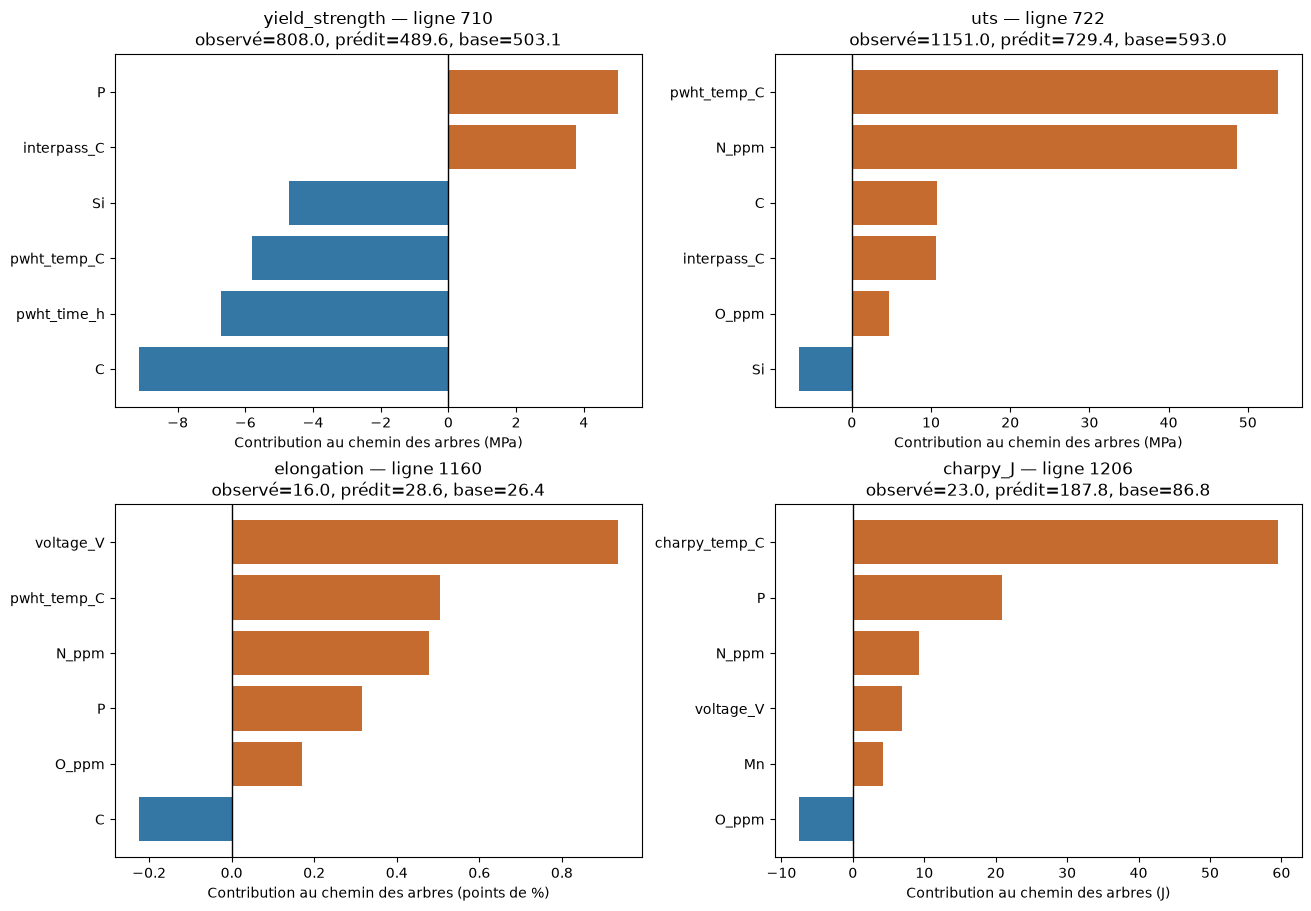

In [9]:
local_rows=[]; local_cases=[]
for target in TARGETS:
    worst=reference_predictions.loc[(reference_predictions.target==target)&
        (reference_predictions.model=='random_forest')].copy()
    worst['abs_error']=(worst.y_true-worst.y_pred).abs()
    worst=worst.nlargest(3,'abs_error')
    for outer,records in worst.groupby('outer_fold'):
        train,valid=outer_partitions(data,target,int(outer)); features=task_features(target)
        selected=reference_scores.loc[(reference_scores.target==target)&
            (reference_scores.model=='random_forest')&(reference_scores.outer_fold==outer)].iloc[0]
        model=make_pipeline('random_forest',target).set_params(**json.loads(selected.best_params))
        with threadpool_limits(limits=1): model.fit(train[features],train[target])
        chosen=valid.loc[valid.raw_row_id.isin(records.raw_row_id)].copy()
        pre=model.named_steps['preprocess']; names=pre.get_feature_names_out()
        baseline,contrib=forest_path_contributions(model.named_steps['model'],pre.transform(chosen[features]))
        pred=model.predict(chosen[features])
        np.testing.assert_allclose(baseline+contrib.sum(axis=1),pred,rtol=1e-10,atol=1e-8)
        for j,(_,row) in enumerate(chosen.iterrows()):
            local_cases.append({'target':target,'raw_row_id':row.raw_row_id,'group':row.group,
                                'outer_fold':outer,'baseline':baseline,'y_true':row[target],
                                'y_pred':pred[j],'abs_error':abs(pred[j]-row[target])})
            for c in features:
                indices=[k for k,name in enumerate(names) if name==c or (c==CAT and name.startswith(CAT+'='))]
                local_rows.append({'target':target,'raw_row_id':row.raw_row_id,'group':row.group,
                    'outer_fold':outer,'feature':c,'observed_value':row[c],
                    'was_missing':pd.isna(row[c]),'contribution':contrib[j,indices].sum(),
                    'unit':TARGET_UNITS[target],'baseline':baseline,'y_true':row[target],'y_pred':pred[j]})
local=pd.DataFrame(local_rows); cases=pd.DataFrame(local_cases)
show_saved(cases.sort_values(['target','abs_error'],ascending=[True,False]),'local_error_cases.csv')
show_saved(local,'local_path_contributions.csv')
fig,axes=plt.subplots(2,2,figsize=(13,9),layout='constrained')
for ax,target in zip(axes.ravel(),TARGETS):
    case=cases.loc[cases.target==target].nlargest(1,'abs_error').iloc[0]
    g=local.loc[(local.target==target)&(local.raw_row_id==case.raw_row_id)].copy()
    g['magnitude']=g.contribution.abs()
    top=g.nlargest(6,'magnitude').sort_values('contribution')
    ax.barh(top.feature,top.contribution,color=np.where(top.contribution>0,'#c66b30','#3577a4'))
    ax.axvline(0,color='black',lw=1)
    ax.set(title=f'{target} — ligne {int(case.raw_row_id)}\nobservé={case.y_true:.1f}, prédit={case.y_pred:.1f}, base={case.baseline:.1f}',
           xlabel=f'Contribution au chemin des arbres ({TARGET_UNITS[target]})')
fig.savefig(OUT/'local_path_contributions.png',dpi=160); plt.show()


## Étape 2 — Audit du protocole Charpy

Méthode : définitions Cambridge → source compilatrice → publications des séries.
Une correspondance exige des compositions/conditions concordantes ; on ne décide
pas d'un protocole à partir d'un histogramme d'énergies. Le document Cambridge
sépare bien température (°C) et énergie (J) : aucune colonne à unités mélangées.

La thèse Cool (1996), §6.4, p.85 et tableau 6.5 p.86 (PDF 105–106), décrit une
prédiction d'énergie avec température d'essai en entrée et limite d'élasticité
parmi ses entrées. Ce modèle historique utilise davantage d'informations que
notre scénario composition/processus ; sa performance n'est pas directement
comparable. L'article Bhadeshia–MacKay–Svensson (1995), pp.4–6 PDF, utilise aussi
YS/microstructure et un partage aléatoire d'exemples.

Pour `SvenGret-1990`, le tableau 1 (p.456-s, PDF 27) et le protocole p.455-s
(PDF 26) confirment 16 compositions et cinq températures, cinq éprouvettes à
chaque température. Les sept colonnes C/Si/Mn/P/S/N/O et les conditions 180 A,
23 V, 1 kJ/mm, 250 °C sont confrontées aux enregistrements. La dernière précision
numérique des énergies issues des figures n'est pas certifiée par cet audit.

Les autres séries restent à différents niveaux de preuve. Le tableau complet
ci-dessous donne une ligne par groupe, une hypothèse séparée du statut validé,
et les références disponibles. Deux groupes E(T) confirmés ne permettent pas un nouveau
benchmark imbriqué externe à cinq groupes/plis ; nous n'inventons pas un sous-ensemble
homogène. Une courbe peut contenir E=100 J sans protocole de transition.

Sources : [Cambridge](https://www.phase-trans.msm.cam.ac.uk/map/data/materials/welddb-b.html),
[Cool, thèse](https://www.phase-trans.msm.cam.ac.uk/2012/Cool_Thesis.pdf),
[Svensson–Gretoft](https://canteach.candu.org/content%20library/20053409.pdf),
[Bhadeshia et al.](https://www.phase-trans.msm.cam.ac.uk/abstracts/toughness.pdf).

Deux autres publications ont été confrontées au master :

- [Evans 1986](https://www.researchgate.net/publication/277011176_The_Effect_of_Stress_Relieving_on_the_Microstructure_and_Properties_of_C-Mn_all-weld-metal_deposits),
  tableau 1 p.327-s/protocole p.326-s : 16 compositions C/Si/Mn et six conditions
  concordent avec les 94 lignes `Evans-StressRelief-1991`. Famille de courbes de
  transition E(T) confirmée ; environ 35 éprouvettes par courbe. L'année de l'ID
  diffère de celle de publication ; valeurs ponctuelles non redigitisées.
- [Evans 1989, chromium](https://www.researchgate.net/publication/326989878_Effect_of_chromium_on_the_microstructure_and_properties_of_C-Mn_all-weld_metal_deposits),
  tableau 1 : 20 compositions C/Si/Mn/Cr concordent. Figures 20/21 : températures
  à 100 J, ce qui étaye l'extraction des 31 couples tous à 100 J. Leur précision
  numérique reste non vérifiée ; le statut marque cette inférence séparément.

21 groupes / 656 lignes restent non résolus. Les deux familles E(T) confirmées
comptent 174 lignes. Aucun filtre de labels ni réentraînement homogène n'est
fabriqué avec ce faible nombre de sources. Le tableau Svensson indique aussi
wt% pour Ti/Al/Sn/As/Sb : cela appuie une correction future par source des cellules
en quarantaine, sans modification globale ni changement du master ici.


In [10]:
# Table 1 manually read and visually checked: source wt% for C/Si/Mn/P/S, ppm N/O.
source_table=pd.DataFrame([
[1,.030,.45,.78,.010,.013,95,336],[2,.032,.45,1.27,.010,.008,94,321],
[3,.031,.42,1.71,.010,.004,109,297],[4,.032,.45,2.05,.010,.002,119,320],
[5,.059,.34,.77,.010,.010,66,306],[6,.059,.33,1.09,.010,.008,64,310],
[7,.059,.30,1.44,.010,.006,65,305],[8,.065,.33,1.83,.010,.003,76,291],
[9,.090,.41,.78,.010,.013,36,421],[10,.089,.35,1.18,.010,.011,73,404],
[11,.088,.37,1.59,.010,.011,77,491],[12,.098,.39,2.25,.014,.008,88,330],
[13,.12,.43,.86,.014,.011,54,329],[14,.12,.44,1.35,.014,.010,55,326],
[15,.13,.37,1.83,.011,.010,63,318],[16,.11,.36,2.18,.011,.008,74,342]],
columns=['sample','C','Si','Mn','P','S','N_ppm','O_ppm'])
charpy=eligible_rows(data,'charpy_J')
sven=charpy.loc[charpy.group=='SvenGret-1990'].copy()
sven['sample']=sven.weld_id.str.extract(r'-(\d+)Ch').astype(int)
matched=sven.merge(source_table,on='sample',suffixes=('_master','_source'),validate='many_to_one')
for c in ['C','Si','Mn','P','S','N_ppm','O_ppm']:
    np.testing.assert_allclose(matched[c+'_master'],matched[c+'_source'],rtol=0,atol=1e-10)
assert len(sven)==80 and sven['sample'].nunique()==16
assert sven.groupby('sample').charpy_temp_C.apply(lambda x:set(x)=={-60,-40,-20,0,20}).all()
for c,v in [('current_A',180),('voltage_V',23),('heat_input_kJmm',1),('interpass_C',250)]:
    assert sven[c].eq(v).all()
save_csv(matched,'charpy_source_composition_match.csv')
candidates=pd.read_csv(DATA/'charpy_protocol_candidates.csv')
audit=charpy.groupby('group').agg(n=('charpy_J','size'),energy_levels=('charpy_J','nunique'),
    temperature_levels=('charpy_temp_C','nunique'),energy_min=('charpy_J','min'),energy_max=('charpy_J','max')).reset_index()
audit=audit.merge(candidates[['group','signature']],on='group',validate='one_to_one')
audit['protocol_status']='unresolved_by_original_series_source'
audit['source_url']=''
audit['evidence']='Signature descriptive seulement ; ne permet pas de conclure au protocole.'
audit.loc[audit.group=='SvenGret-1990',['protocol_status','source_url','evidence']]=[
    'confirmed_E_at_preselected_temperatures','https://canteach.candu.org/content%20library/20053409.pdf',
    'Table 1: 16 compositions × 7 colonnes concordantes ; 80 lignes/5 températures ; conditions concordantes ; figures, précision énergie non certifiée.']
# Additional source matches based on primary author-uploaded original papers.
STRESS_URL='https://www.researchgate.net/publication/277011176_The_Effect_of_Stress_Relieving_on_the_Microstructure_and_Properties_of_C-Mn_all-weld-metal_deposits'
CR_URL='https://www.researchgate.net/publication/326989878_Effect_of_chromium_on_the_microstructure_and_properties_of_C-Mn_all-weld_metal_deposits'
stress_source=pd.DataFrame([
['0.045A',.043,.30,.69],['0.045B',.042,.31,.98],['0.045C',.045,.31,1.39],['0.045D',.045,.29,1.83],
['0.065A',.058,.33,.63],['0.065B',.065,.34,.97],['0.065C',.066,.35,1.36],['0.065D',.074,.36,1.80],
['0.095A',.089,.35,.68],['0.095B',.095,.36,1.05],['0.095C',.088,.34,1.33],['0.095D',.089,.33,1.69],
['0.145A',.151,.36,.63],['0.145B',.147,.36,1.02],['0.145C',.147,.35,1.38],['0.145D',.145,.35,1.76]],
columns=['sample','C','Si','Mn'])
stress=charpy.loc[charpy.group=='Evans-StressRelief-1991'].copy()
stress['sample']=stress.weld_id.str.extract(r'1991-([0-9.]+[A-D])ch')
stress_match=stress.merge(stress_source,on='sample',suffixes=('_master','_source'),validate='many_to_one')
for c in ['C','Si','Mn']:
    np.testing.assert_allclose(stress_match[c+'_master'],stress_match[c+'_source'],rtol=0,atol=1e-10)
assert len(stress_match)==94 and stress_match['sample'].nunique()==16
for c,v in [('current_A',170),('voltage_V',21),('heat_input_kJmm',1),('interpass_C',200),('pwht_temp_C',580),('pwht_time_h',2)]:
    assert stress[c].eq(v).all()
save_csv(stress_match,'charpy_stress_relief_source_match.csv')
audit.loc[audit.group=='Evans-StressRelief-1991',['protocol_status','source_url','evidence']]=[
    'confirmed_transition_curve_E_T_family',STRESS_URL,
    'Evans 1986 p.326-s/327-s, table 1: 16 C/Si/Mn compositions and 6 conditions match 94 rows; about 35 specimens per full transition curve. Identifier year 1991 differs. Per-point digitization precision not verified.']
# Table 1 chromium paper (1989): all 20 compositions match, including unlabeled rows.
cr_source=pd.DataFrame([
['0A',.037,.30,.65,.00],['0B',.037,.31,1.03,.00],['0C',.044,.35,1.43,.00],['0D',.045,.33,1.85,.00],
['0.25A',.038,.30,.65,.22],['0.25B',.041,.32,1.01,.24],['0.25C',.044,.32,1.45,.24],['0.25D',.048,.33,1.85,.26],
['0.5A',.040,.33,.60,.51],['0.5B',.043,.31,.95,.53],['0.5C',.047,.33,1.42,.53],['0.5D',.051,.33,1.83,.52],
['1.0A',.041,.30,.59,1.00],['1.0B',.045,.32,.97,1.04],['1.0C',.048,.33,1.37,1.08],['1.0D',.052,.33,1.81,1.10],
['2.3A',.041,.27,.59,2.34],['2.3B',.046,.30,.93,2.38],['2.3C',.050,.31,1.29,2.32],['2.3D',.054,.33,1.72,2.36]],
columns=['sample','C','Si','Mn','Cr'])
cr=master.loc[master.group=='Evans-Cr/CMn-1989'].copy()
cr['sample']=cr.weld_id.str.extract(r'1989-([0-9.]+[A-D])-')
cr_match=cr.merge(cr_source,on='sample',suffixes=('_master','_source'),validate='many_to_one')
for c in ['C','Si','Mn','Cr']:
    np.testing.assert_allclose(cr_match[c+'_master'],cr_match[c+'_source'],rtol=0,atol=1e-10)
assert cr_match['sample'].nunique()==20
save_csv(cr_match,'charpy_chromium_source_match.csv')
audit.loc[audit.group=='Evans-Cr/CMn-1989',['protocol_status','source_url','evidence']]=[
    'source_matched_threshold_sampling_likely',CR_URL,
    'Evans 1989 table 1: 20 compositions C/Si/Mn/Cr match; figs 20/21 present T at 100J. 31 reported Charpy pairs all have E=100J. Sampling inference supported by source; numerical temperatures not independently digitized.']
# All unknown groups stay unknown; no threshold-only relabeling or filtered retraining.
show_saved(audit,'charpy_source_audit.csv',30)
signature_errors=reference_predictions.loc[(reference_predictions.target=='charpy_J')&
    (reference_predictions.model=='random_forest')].merge(audit[['group','signature','protocol_status']],on='group',validate='many_to_one')
show_saved(pd.DataFrame([dict(signature=s,status=st,n=len(g),groups=g.group.nunique(),
                           **regression_metrics(g.y_true,g.y_pred))
                       for (s,st),g in signature_errors.groupby(['signature','protocol_status'])]),
           'charpy_protocol_error_diagnostics.csv')


,group,n,energy_levels,temperature_levels,energy_min,energy_max,signature,protocol_status,source_url,evidence
0,Blond&-1984,6,4,6,40.0,118.0,varying_E,unresolved_by_original_series_source,,Signature descriptive seulement ; ne permet pa...
1,Chandel&-1985,19,18,8,15.0,270.0,varying_E,unresolved_by_original_series_source,,Signature descriptive seulement ; ne permet pa...
2,Ditt,14,13,4,141.0,233.0,varying_E,unresolved_by_original_series_source,,Signature descriptive seulement ; ne permet pa...
3,Evans-Al/CMn-1990,35,2,26,28.0,100.0,fixed_energy_varying_T,unresolved_by_original_series_source,,Signature descriptive seulement ; ne permet pa...
4,Evans-AlTi-1994,60,2,42,28.0,100.0,fixed_energy_varying_T,unresolved_by_original_series_source,,Signature descriptive seulement ; ne permet pa...
5,Evans-B/9Cr1Mo-1994,24,3,21,28.0,100.0,mixed_unresolved,unresolved_by_original_series_source,,Signature descriptive seulement ; ne permet pa...
6,Evans-Cr/CMn-1989,31,1,23,100.0,100.0,fixed_energy_varying_T,source_matched_threshold_sampling_likely,https://www.researchgate.net/publication/32698...,Evans 1989 table 1: 20 compositions C/Si/Mn/Cr...
7,Evans-Mn-1977,8,1,7,100.0,100.0,mixed_unresolved,unresolved_by_original_series_source,,Signature descriptive seulement ; ne permet pa...
8,Evans-Nb/Mn-1991,78,1,47,100.0,100.0,fixed_energy_varying_T,unresolved_by_original_series_source,,Signature descriptive seulement ; ne permet pa...
9,Evans-Ni/CMn-1990,30,1,21,100.0,100.0,fixed_energy_varying_T,unresolved_by_original_series_source,,Signature descriptive seulement ; ne permet pa...


,signature,status,n,groups,MAE,RMSE,R2
0,fixed_energy_varying_T,source_matched_threshold_sampling_likely,31,1,18.149677,29.507012,NaN
1,fixed_energy_varying_T,unresolved_by_original_series_source,423,11,20.596908,28.266235,0.224090
2,mixed_unresolved,unresolved_by_original_series_source,40,3,28.249450,35.788445,-0.500765
3,varying_E,confirmed_E_at_preselected_temperatures,80,1,40.641938,46.290737,0.307708
4,varying_E,confirmed_transition_curve_E_T_family,94,1,60.822271,71.510349,-0.048044
5,varying_E,unresolved_by_original_series_source,193,7,55.565543,67.258122,-0.103029


## Étape 3 — Sensibilités comparables et réglages internes

Méthode fixée avant les recherches : **3 schémas × 2 imputations × 4 modèles ×
4 cibles × 5 plis = 480 évaluations externes prévues**. Même cohorte strict13 et
mêmes labels/plis ; Ni/Cr/Mo non rapportés ne deviennent pas zéro. Aucun nouveau
filtre complet sur 16 colonnes. Les grilles sont celles du benchmark 03.

Avant chaque recherche, les trois trains internes et le train externe doivent
produire des transformations finies et convergées. Échec explicite → combinaison
cible/pli indisponible, sans bascule silencieuse vers la médiane. Les fits réussis
sont mis en cache sur leurs entrées/paramètres exacts, jamais sur le dataset global.

Chaque recherche calcule MAE et MSE internes. Le modèle principal est choisi par
MAE interne. Sur A1_13/itérative, un contrôle est aussi choisi par **MSE interne** :
il est mieux aligné avec RMSE/R² (sur une même validation, SST ne dépend pas du
modèle). Aucune sélection par R² externe. La moyenne des MSE des plis est le
critère explicite, pas un « R² interne moyen ».

Enfin, sélectionner conjointement schéma/imputation/famille à l'intérieur de
chaque train externe ; en cas d'échec d'un pli interne, exclure ce candidat,
consigner le motif et poursuivre avec les candidats valides. Cette règle ne
consulte pas les labels externes. Ne pas annoncer le meilleur scénario du tableau
externe comme une estimation indépendante du modèle sélectionné.

In [10]:
cache=Memory(OUT/'pipeline_cache',verbose=0)
sensitivity_scores=[]; sensitivity_predictions=[]; searches=[]; checks=[]; failures=[]
mse_scores=[]; mse_predictions=[]; joint_scores=[]; joint_predictions=[]

for target in TARGETS:
    for outer in range(5):
        train,valid=outer_partitions(data,target,outer)
        cv=inner_splits(train,outer)
        eligible_candidates=[]
        for feature_set in FEATURE_SETS:
            for imputer in IMPUTERS:
                features=case_features(target,feature_set)
                context={'target':target,'outer_fold':outer,'feature_set':feature_set,'imputer':imputer}
                try:
                    for partition, idx in [('outer',np.arange(len(train)))] + [(f'inner{i}',tr) for i,(tr,_) in enumerate(cv)]:
                        pre=FoldPreprocessor(features[:-1],method=imputer).fit(train.iloc[idx][features])
                        Z=pre.transform(train.iloc[idx][features])
                        assert np.isfinite(Z).all()
                        # Ensure all observed values remain exactly represented after transformation.
                        observed=train.iloc[idx][features[:-1]].to_numpy(float)
                        restored=Z[:,:len(features)-1]*pre.sd_+pre.mu_
                        mask=~np.isnan(observed)
                        np.testing.assert_allclose(restored[mask],observed[mask],atol=1e-8,rtol=1e-8)
                        # Validation transformation can fail (e.g. unsupported PWHT pair); check before model fit.
                        other=valid if partition=='outer' else train.iloc[cv[int(partition[-1])][1]]
                        assert np.isfinite(pre.transform(other[features])).all()
                        checks.append(dict(**context,partition=partition,n_train=len(idx),iterations=pre.n_iter_,status='ok'))
                except (ValueError,RuntimeError,AssertionError) as exc:
                    failures.append(dict(**context,model='all',stage='preflight',reason=str(exc)))
                    print('COMBINAISON INDISPONIBLE',context,str(exc),flush=True)
                    continue
                for model_name in FAMILIES:
                    pipeline=make_case(model_name,target,feature_set,imputer,cache)
                    search=GridSearchCV(pipeline,PARAM_GRIDS[model_name],scoring=SCORING,
                        refit='MAE',cv=cv,n_jobs=N_JOBS,error_score='raise',return_train_score=False)
                    started=time.perf_counter()
                    try:
                        with parallel_config(backend='threading'),threadpool_limits(limits=1):
                            search.fit(train[features],train[target])
                    except (ValueError,RuntimeError) as exc:
                        failures.append(dict(**context,model=model_name,stage='search',reason=str(exc)))
                        print('RECHERCHE INDISPONIBLE',context,model_name,str(exc),flush=True)
                        continue
                    pred=search.predict(valid[features])
                    train_pred=search.predict(train[features])
                    sensitivity_scores.append(dict(**context,model=model_name,
                        best_params=json.dumps(search.best_params_,sort_keys=True),
                        inner_MAE=-search.best_score_,elapsed_seconds=time.perf_counter()-started,
                        **regression_metrics(valid[target],pred),
                        **{'train_'+k:v for k,v in regression_metrics(train[target],train_pred).items()}))
                    prediction_frame=valid[['raw_row_id','group','outer_fold']].copy()
                    prediction_frame=prediction_frame.assign(target=target,model=model_name,
                        feature_set=feature_set,imputer=imputer,y_true=valid[target].to_numpy(),y_pred=pred)
                    sensitivity_predictions.append(prediction_frame)
                    results=search.cv_results_
                    for candidate,params in enumerate(results['params']):
                        searches.append(dict(**context,model=model_name,candidate=candidate,
                            params=json.dumps(params,sort_keys=True),inner_MAE=-results['mean_test_MAE'][candidate],
                            inner_MSE=-results['mean_test_MSE'][candidate],
                            **{f'inner{i}_MAE':-results[f'split{i}_test_MAE'][candidate] for i in range(3)},
                            **{f'inner{i}_MSE':-results[f'split{i}_test_MSE'][candidate] for i in range(3)}))
                    eligible_candidates.append((search.best_score_,feature_set,imputer,model_name,
                                                search.best_params_,search.best_estimator_))
                    if feature_set=='A1_13' and imputer=='iterative':
                        best_mse=int(np.argmax(results['mean_test_MSE']))
                        mse_params=results['params'][best_mse]
                        mse_model=make_case(model_name,target,feature_set,imputer,cache).set_params(**mse_params)
                        with threadpool_limits(limits=1): mse_model.fit(train[features],train[target])
                        mse_pred=mse_model.predict(valid[features])
                        mse_scores.append(dict(**context,model=model_name,
                            best_params=json.dumps(mse_params,sort_keys=True),inner_MSE=-results['mean_test_MSE'][best_mse],
                            **regression_metrics(valid[target],mse_pred)))
                        mse_predictions.append(prediction_frame.assign(y_pred=mse_pred))
                    print(f'{target} pli {outer} {feature_set}/{imputer} {model_name} : '
                          f'MAE={sensitivity_scores[-1]["MAE"]:.3f}, R²={sensitivity_scores[-1]["R2"]:.3f} '
                          f'({time.perf_counter()-started:.1f}s)',flush=True)
                    save_csv(pd.DataFrame(sensitivity_scores),'sensitivity_outer_metrics.csv')
                    save_csv(pd.concat(sensitivity_predictions,ignore_index=True),'sensitivity_outer_predictions.csv')
                    save_csv(pd.DataFrame(searches),'sensitivity_inner_search.csv')
                save_csv(pd.DataFrame(checks),'sensitivity_preflight.csv')
                save_csv(pd.DataFrame(failures,columns=['target','outer_fold','feature_set','imputer','model','stage','reason']),
                         'sensitivity_failures.csv')
        if not eligible_candidates: raise RuntimeError('Aucun candidat interne valide.')
        # Python max is stable: ties follow predeclared set/imputer/model ordering.
        best=max(eligible_candidates,key=lambda item:item[0])
        internal,feature_set,imputer,model_name,params,selected=best
        pred=selected.predict(valid[case_features(target,feature_set)])
        joint_scores.append({'target':target,'outer_fold':outer,'feature_set':feature_set,
            'imputer':imputer,'model':model_name,'inner_MAE':-internal,
            'best_params':json.dumps(params,sort_keys=True),**regression_metrics(valid[target],pred)})
        joint_predictions.append(valid[['raw_row_id','group','outer_fold']].assign(target=target,
            model='joint_inner_selection',y_true=valid[target].to_numpy(),y_pred=pred))
        save_csv(pd.DataFrame(joint_scores),'joint_inner_selection_metrics.csv')
        save_csv(pd.concat(joint_predictions,ignore_index=True),'joint_inner_selection_predictions.csv')
        save_csv(pd.DataFrame(mse_scores),'mse_selected_metrics.csv')
        if mse_predictions: save_csv(pd.concat(mse_predictions,ignore_index=True),'mse_selected_predictions.csv')

save_csv(pd.DataFrame(checks),'sensitivity_preflight.csv')
save_csv(pd.DataFrame(failures,columns=['target','outer_fold','feature_set','imputer','model','stage','reason']), 'sensitivity_failures.csv')


yield_strength pli 0 A0_11/median ridge : MAE=54.718, R²=0.064 (0.2s)


yield_strength pli 0 A0_11/median svr_rbf : MAE=56.781, R²=0.049 (0.5s)


yield_strength pli 0 A0_11/median random_forest : MAE=52.434, R²=0.205 (11.7s)


yield_strength pli 0 A0_11/median knn : MAE=55.572, R²=0.063 (0.2s)


yield_strength pli 0 A0_11/iterative ridge : MAE=54.559, R²=0.066 (1.0s)


...

charpy_J pli 4 A1b_16/median ridge : MAE=39.041, R²=0.238 (0.3s)


charpy_J pli 4 A1b_16/median svr_rbf : MAE=39.878, R²=0.196 (0.6s)


charpy_J pli 4 A1b_16/median random_forest : MAE=32.244, R²=0.425 (13.5s)


charpy_J pli 4 A1b_16/median knn : MAE=40.540, R²=0.098 (0.3s)


COMBINAISON INDISPONIBLE {'target': 'charpy_J', 'outer_fold': 4, 'feature_set': 'A1b_16', 'imputer': 'iterative'} Imputation itérative non convergée : réviser le schéma dans le train.


### Résultats, gains appariés et limites

Moyennes des cinq plis et prédictions OOF : les cas sans cinq plis ne constituent
pas une comparaison complète. Les écarts externes de scénarios restent descriptifs.
La sélection conjointe possède sa propre évaluation externe. Le contrôle MSE
répond à l'hypothèse « objectif de réglage mal aligné avec R² ».

Les gains appariés A1b_16 − A1_13 sont calculés sur les mêmes lignes. Les intervalles
bootstrap par groupes restent conditionnels aux modèles entraînés. Une faible
importance ou un gain négatif ne signifie pas que Ni/Cr/Mo sont physiquement
sans effet : plus de la moitié des valeurs sont manquantes dans cette cohorte.

La synthèse de sélection conjointe affiche les scores OOF réunis. Les tableaux
par configuration affichent aussi la moyenne des cinq scores externes. Un R²
non défini pour une population à énergie constante est laissé vide (NaN).


In [11]:
# Reconcile unavailable cases before summarizing; also protects interrupted reruns.
completed=pd.read_csv(OUT/'sensitivity_outer_metrics.csv')
recorded=pd.read_csv(OUT/'sensitivity_failures.csv')
for target in TARGETS:
    for outer in range(5):
        for schema in FEATURE_SETS:
            for method in IMPUTERS:
                present=completed.loc[(completed.target==target)&(completed.outer_fold==outer)&
                    (completed.feature_set==schema)&(completed.imputer==method)]
                failure=recorded.loc[(recorded.target==target)&(recorded.outer_fold==outer)&
                    (recorded.feature_set==schema)&(recorded.imputer==method)]
                if len(present) or len(failure):
                    continue
                # If a final `continue` preceded the last CSV save, reproduce the failure.
                train,valid=outer_partitions(data,target,outer)
                cv=inner_splits(train,outer); features=case_features(target,schema)
                try:
                    for partition,idx in [('outer',np.arange(len(train)))]+[(f'inner{i}',tr) for i,(tr,_) in enumerate(cv)]:
                        pre=FoldPreprocessor(features[:-1],method=method).fit(train.iloc[idx][features])
                        other=valid if partition=='outer' else train.iloc[cv[int(partition[-1])][1]]
                        assert np.isfinite(pre.transform(other[features])).all()
                except (ValueError,RuntimeError,AssertionError) as exc:
                    recorded=pd.concat([recorded,pd.DataFrame([{'target':target,'outer_fold':outer,
                        'feature_set':schema,'imputer':method,'model':'all','stage':'preflight','reason':str(exc)}])],ignore_index=True)
                    print('Échec final reproduit et enregistré :',target,outer,schema,method,str(exc))
                else:
                    raise AssertionError(f'Évaluation manquante sans échec reproduit : {target}/{outer}/{schema}/{method}')
save_csv(recorded,'sensitivity_failures.csv')

sensitivity=pd.read_csv(OUT/'sensitivity_outer_metrics.csv')
spred=pd.read_csv(OUT/'sensitivity_outer_predictions.csv')
keys=['target','feature_set','imputer','model']
summary=sensitivity.groupby(keys).agg(MAE_mean=('MAE','mean'),MAE_sd=('MAE','std'),
    RMSE_mean=('RMSE','mean'),R2_mean=('R2','mean'),R2_sd=('R2','std'),
    train_MAE=('train_MAE','mean'),train_R2=('train_R2','mean'),folds=('outer_fold','nunique')).reset_index()
oof=pd.DataFrame([dict(zip(keys,key),**{'OOF_'+k:v for k,v in regression_metrics(g.y_true,g.y_pred).items()})
                  for key,g in spred.groupby(keys)])
summary=summary.set_index(keys).reindex(pd.MultiIndex.from_product(
    [TARGETS,list(FEATURE_SETS),IMPUTERS,FAMILIES],names=keys)).reset_index()
summary['folds']=summary.folds.fillna(0).astype(int)
summary=summary.merge(oof,on=keys,how='left',validate='one_to_one')
save_csv(summary,'sensitivity_summary.csv')
for target in TARGETS:
    display(summary.loc[summary.target==target])
# Reference equality is a strong regression check on the original configuration.
reproduced=spred.loc[(spred.feature_set=='A1_13')&(spred.imputer=='iterative')].merge(
    reference_predictions,on=['target','model','raw_row_id','group','outer_fold'],suffixes=('_new','_old'),validate='one_to_one')
assert len(reproduced)==len(reference_predictions.loc[reference_predictions.model!='median_y'])
np.testing.assert_allclose(reproduced.y_pred_new,reproduced.y_pred_old,atol=1e-8,rtol=1e-10)
show_saved(pd.DataFrame([dict(target=t,**regression_metrics(g.y_true,g.y_pred))
                        for t,g in pd.read_csv(OUT/'joint_inner_selection_predictions.csv').groupby('target')]),
           'joint_inner_selection_summary.csv')
mse_summary=pd.read_csv(OUT/'mse_selected_metrics.csv').groupby(['target','model']).agg(
    MAE_mean=('MAE','mean'),RMSE_mean=('RMSE','mean'),R2_mean=('R2','mean')).reset_index()
show_saved(mse_summary,'mse_selected_summary.csv')
paired_gains=[]
for target in TARGETS:
    for model in FAMILIES:
        for imputer in IMPUTERS:
            mask=(spred.target==target)&(spred.model==model)&(spred.imputer==imputer)
            a=spred.loc[mask&(spred.feature_set=='A1_13'),['raw_row_id','y_true','y_pred']].copy()
            a['aerr']=(a.y_true-a.y_pred).abs()
            b=spred.loc[mask&(spred.feature_set=='A1b_16'),['raw_row_id','group','y_true','y_pred']].copy()
            b['berr']=(b.y_true-b.y_pred).abs()
            both=b.merge(a[['raw_row_id','aerr']],on='raw_row_id',validate='one_to_one')
            if len(both)!=len(eligible_rows(data,target)):
                paired_gains.append({'target':target,'model':model,'imputer':imputer,'status':'incomplete'})
                continue
            both['gain']=both.aerr-both.berr
            paired_gains.append(dict(target=target,model=model,imputer=imputer,status='ok',**paired_group_bootstrap(both)))
show_saved(pd.DataFrame(paired_gains),'extension16_paired_gains.csv',40)

Échec final reproduit et enregistré : charpy_J 4 A1b_16 iterative Imputation itérative non convergée : réviser le schéma dans le train.


,target,feature_set,imputer,model,MAE_mean,MAE_sd,RMSE_mean,R2_mean,R2_sd,train_MAE,train_R2,folds,OOF_MAE,OOF_RMSE,OOF_R2
0,yield_strength,A0_11,median,ridge,70.745043,9.734808,91.607065,-0.058083,0.118511,67.300972,0.077051,5,70.993044,92.797155,-0.017749
1,yield_strength,A0_11,median,svr_rbf,74.901093,14.705870,95.857278,-0.152127,0.190617,38.752145,0.622415,5,75.449981,97.629837,-0.126514
2,yield_strength,A0_11,median,random_forest,68.977948,12.775833,89.276081,0.000139,0.191286,27.897514,0.812388,5,69.739096,91.702721,0.006116
3,yield_strength,A0_11,median,knn,77.896024,18.424243,103.061463,-0.324760,0.330952,47.033716,0.496963,5,78.677715,106.542667,-0.341586
4,yield_strength,A0_11,iterative,ridge,70.508991,9.769776,91.339426,-0.051678,0.114566,67.228386,0.076515,5,70.739684,92.502237,-0.011290
5,yield_strength,A0_11,iterative,svr_rbf,76.721875,16.489141,98.943939,-0.229530,0.293782,39.059764,0.615865,5,77.465444,101.696311,-0.222311
6,yield_strength,A0_11,iterative,random_forest,69.135915,13.898990,89.271882,-0.001339,0.227159,27.909319,0.810817,5,70.091237,92.054529,-0.001525
7,yield_strength,A0_11,iterative,knn,78.863341,19.668300,103.600702,-0.340111,0.359922,46.147333,0.498717,5,79.916997,107.401736,-0.363308
8,yield_strength,A1_13,median,ridge,71.141798,5.387745,92.003144,-0.077363,0.139910,64.669744,0.153703,5,71.309582,92.760012,-0.016935
9,yield_strength,A1_13,median,svr_rbf,67.653728,10.704621,87.370504,0.039295,0.128328,33.140524,0.679830,5,68.379454,89.035192,0.063097


,target,feature_set,imputer,model,MAE_mean,MAE_sd,RMSE_mean,R2_mean,R2_sd,train_MAE,train_R2,folds,OOF_MAE,OOF_RMSE,OOF_R2
24,uts,A0_11,median,ridge,71.336711,12.049446,90.097036,-0.118967,0.191310,65.482921,0.123470,5,70.250350,89.754624,-0.006391
25,uts,A0_11,median,svr_rbf,66.980694,11.854128,86.915342,-0.059047,0.261240,28.826861,0.726771,5,65.761302,86.312963,0.069309
26,uts,A0_11,median,random_forest,57.311884,9.011264,76.544991,0.179500,0.175773,24.292002,0.841826,5,56.357247,76.166561,0.275260
27,uts,A0_11,median,knn,70.889337,20.271369,93.927607,-0.214551,0.355908,40.916291,0.586904,5,68.803545,93.890649,-0.101281
28,uts,A0_11,iterative,ridge,71.347876,11.840823,90.262707,-0.125728,0.176973,64.010122,0.151417,5,70.242313,89.805851,-0.007541
29,uts,A0_11,iterative,svr_rbf,68.374815,14.454542,91.527740,-0.222071,0.592428,32.514141,0.680022,5,66.954554,91.403770,-0.043714
30,uts,A0_11,iterative,random_forest,58.377244,8.954884,77.657508,0.151187,0.194569,23.577848,0.835887,5,57.419224,77.199531,0.255469
31,uts,A0_11,iterative,knn,69.947736,19.917812,93.017717,-0.180585,0.282984,43.854065,0.531667,5,67.873461,92.931354,-0.078892
32,uts,A1_13,median,ridge,69.423025,10.544303,88.753490,-0.106717,0.235970,61.485324,0.216837,5,68.436029,88.129186,0.029730
33,uts,A1_13,median,svr_rbf,65.442162,9.240526,83.670952,0.021923,0.177189,28.249894,0.738752,5,64.474980,83.145088,0.136372


,target,feature_set,imputer,model,MAE_mean,MAE_sd,RMSE_mean,R2_mean,R2_sd,train_MAE,train_R2,folds,OOF_MAE,OOF_RMSE,OOF_R2
48,elongation,A0_11,median,ridge,4.092702,0.298190,4.997587,-0.078170,0.066669,3.789144,0.110379,5,4.084259,4.990582,-0.045779
49,elongation,A0_11,median,svr_rbf,4.121608,0.447957,5.053488,-0.110949,0.175648,2.426121,0.554925,5,4.085169,5.029959,-0.062347
50,elongation,A0_11,median,random_forest,3.690304,0.293360,4.614727,0.075587,0.115932,1.629248,0.794137,5,3.675315,4.602150,0.110678
51,elongation,A0_11,median,knn,4.151181,0.396726,5.178702,-0.176026,0.249581,2.750828,0.488968,5,4.150132,5.208713,-0.139196
52,elongation,A0_11,iterative,ridge,4.088850,0.316890,4.988918,-0.074080,0.072417,3.788064,0.110677,5,4.078882,4.982275,-0.042301
53,elongation,A0_11,iterative,svr_rbf,4.135229,0.435365,5.068557,-0.117158,0.167541,2.455962,0.548425,5,4.101101,5.044079,-0.068320
54,elongation,A0_11,iterative,random_forest,3.678775,0.283305,4.646820,0.063299,0.096619,1.414594,0.842992,5,3.669599,4.636807,0.097233
55,elongation,A0_11,iterative,knn,4.158203,0.409262,5.168033,-0.171619,0.255028,2.739591,0.485186,5,4.157750,5.199007,-0.134954
56,elongation,A1_13,median,ridge,3.950064,0.341815,5.262291,-0.227207,0.412073,3.361294,0.286698,5,3.947862,5.230500,-0.148746
57,elongation,A1_13,median,svr_rbf,3.888581,0.370707,4.832862,-0.007946,0.101719,2.294512,0.583523,5,3.866365,4.825741,0.022165


,target,feature_set,imputer,model,MAE_mean,MAE_sd,RMSE_mean,R2_mean,R2_sd,train_MAE,train_R2,folds,OOF_MAE,OOF_RMSE,OOF_R2
72,charpy_J,A0_11,median,ridge,35.287610,10.412369,45.396580,0.066148,0.177587,34.104268,0.270492,5,35.679479,46.260201,0.160881
73,charpy_J,A0_11,median,svr_rbf,38.685413,9.043828,50.668319,-0.183607,0.335188,19.765713,0.703549,5,38.946439,51.299108,-0.031878
74,charpy_J,A0_11,median,random_forest,35.138777,12.019244,46.620040,0.017548,0.235194,10.364868,0.912294,5,35.394119,47.529053,0.114218
75,charpy_J,A0_11,median,knn,37.575678,9.531993,51.755619,-0.256308,0.393756,17.700600,0.733188,5,37.918106,52.152830,-0.066509
76,charpy_J,A0_11,iterative,ridge,36.048087,12.291900,46.238753,0.048052,0.135022,34.416108,0.243991,5,36.459716,47.428462,0.117963
77,charpy_J,A0_11,iterative,svr_rbf,38.710453,8.993218,50.898348,-0.206396,0.415438,19.029607,0.720979,5,38.954172,51.515318,-0.040595
78,charpy_J,A0_11,iterative,random_forest,34.711264,12.016306,46.782554,0.002236,0.291904,8.282777,0.939664,5,34.968650,47.623203,0.110705
79,charpy_J,A0_11,iterative,knn,37.763498,10.041852,50.622468,-0.253651,0.710639,19.008801,0.702592,5,38.061685,51.719514,-0.048860
80,charpy_J,A1_13,median,ridge,37.303958,15.266825,53.969287,-0.233292,0.608908,32.566213,0.326594,5,37.763536,59.831361,-0.403675
81,charpy_J,A1_13,median,svr_rbf,35.065631,8.081052,44.835946,0.090900,0.163758,17.252736,0.762879,5,35.373965,45.675007,0.181976


,target,MAE,RMSE,R2
0,charpy_J,36.420126,49.616016,0.034722
1,elongation,3.476143,4.392663,0.189798
2,uts,53.749090,69.244704,0.401001
3,yield_strength,57.535298,75.344257,0.329079


,target,model,MAE_mean,RMSE_mean,R2_mean
0,charpy_J,knn,35.145899,48.031831,-0.073674
1,charpy_J,random_forest,34.265668,46.228911,0.027004
2,charpy_J,ridge,35.737089,45.838892,0.071600
3,charpy_J,svr_rbf,36.577485,46.315899,0.039715
4,elongation,knn,3.910961,5.017593,-0.092548
5,elongation,random_forest,3.598525,4.513036,0.115610
6,elongation,ridge,3.789636,4.635872,0.071237
7,elongation,svr_rbf,3.899002,4.828199,-0.008643
8,uts,knn,69.138883,91.061161,-0.129234
9,uts,random_forest,57.429399,75.811015,0.205764


,target,model,imputer,status,gain_MAE,group_bootstrap_low,group_bootstrap_high,groups
0,yield_strength,ridge,median,ok,2.152606,-3.272968,7.907412,40.0
1,yield_strength,ridge,iterative,incomplete,NaN,NaN,NaN,NaN
2,yield_strength,svr_rbf,median,ok,8.470289,2.148548,17.139366,40.0
3,yield_strength,svr_rbf,iterative,incomplete,NaN,NaN,NaN,NaN
4,yield_strength,random_forest,median,ok,11.057935,3.092985,20.187739,40.0
5,yield_strength,random_forest,iterative,incomplete,NaN,NaN,NaN,NaN
6,yield_strength,knn,median,ok,2.998709,-1.689504,9.164455,40.0
7,yield_strength,knn,iterative,incomplete,NaN,NaN,NaN,NaN
8,uts,ridge,median,ok,7.455984,-1.115602,17.275596,39.0
9,uts,ridge,iterative,incomplete,NaN,NaN,NaN,NaN


### Diagnostic contrôlé de reconstruction Ni/Cr/Mo

Masquer 20 % des valeurs initialement connues de chaque colonne Ni/Cr/Mo en
validation cible/pli (seed42+pli), avec les mêmes masques pour les deux méthodes.
Imputer ajusté uniquement sur les lignes train, aucune cible utilisée. Évaluer
l'erreur en wt%. Les échecs de convergence sont consignés ; le tableau comparatif
ne garde que les mêmes valeurs des contextes réussis **pour les deux méthodes**.
Le mécanisme artificiel ne reproduit pas forcément les absences naturelles.
Ces résultats ne servent pas à choisir les modèles sur les labels externes.

In [12]:
# Hold out known Ni/Cr/Mo entries ONLY for a reconstruction diagnostic, never for training label selection.
mask_rows=[]
for target in TARGETS:
    for outer in range(5):
        train,valid=outer_partitions(data,target,outer); features=case_features(target,'A1b_16')
        rng=np.random.default_rng(SEED+outer)
        hidden={}
        masked=valid[features].copy()
        for c in ['Ni','Cr','Mo']:
            known=np.flatnonzero(valid[c].notna())
            indices=rng.choice(known,size=max(1,int(np.ceil(.2*len(known)))),replace=False) if len(known) else np.array([],dtype=int)
            hidden[c]=indices
            masked.loc[masked.index[indices],c]=np.nan
        for method in IMPUTERS:
            try:
                with threadpool_limits(limits=1):
                    pre=FoldPreprocessor(features[:-1],method=method).fit(train[features])
                    restored=pre.transform(masked)[:,:len(features)-1]*pre.sd_+pre.mu_
            except (RuntimeError,ValueError) as exc:
                mask_rows.append({'target':target,'outer_fold':outer,'imputer':method,'status':'failed','reason':str(exc)})
                continue
            for c,indices in hidden.items():
                k=features.index(c)
                for index in indices:
                    true=valid.iloc[index][c]; predicted=restored[index,k]
                    mask_rows.append({'target':target,'outer_fold':outer,'imputer':method,'status':'ok',
                        'feature':c,'raw_row_id':valid.iloc[index].raw_row_id,'group':valid.iloc[index].group,
                        'true_observed':true,'imputed_after_masking':predicted,
                        'absolute_error':abs(predicted-true),'squared_error':(predicted-true)**2,
                        'unit':'wt%','iterations':pre.n_iter_})
        print('Reconstruction contrôlée',target,outer,flush=True)
mask=pd.DataFrame(mask_rows)
save_csv(mask,'extension16_masked_imputation_rows.csv')
save_csv(mask.loc[mask.status=='failed'],'extension16_masked_imputation_failures.csv')
ok=mask.loc[mask.status=='ok'].copy()
paired_count=ok.groupby(['target','outer_fold','feature','raw_row_id']).imputer.transform('nunique')
common=ok.loc[paired_count==2]
show_saved(common.groupby(['target','imputer','feature']).agg(
    n=('absolute_error','size'),MAE=('absolute_error','mean'),MSE=('squared_error','mean')).reset_index(),
    'extension16_masked_imputation_summary.csv',40)
# All attempts remain in the row export; aggregate comparison uses common successful contexts.


Reconstruction contrôlée yield_strength 0


Reconstruction contrôlée yield_strength 1


Reconstruction contrôlée yield_strength 2


Reconstruction contrôlée yield_strength 3


Reconstruction contrôlée yield_strength 4


...

Reconstruction contrôlée charpy_J 1


Reconstruction contrôlée charpy_J 2


Reconstruction contrôlée charpy_J 3


Reconstruction contrôlée charpy_J 4


,target,imputer,feature,n,MAE,MSE
0,charpy_J,iterative,Cr,40,4.791926,38.464795
1,charpy_J,iterative,Mo,30,1.059564,1.270406
2,charpy_J,iterative,Ni,33,1.034701,1.676409
3,charpy_J,median,Cr,40,1.504000,2.953840
4,charpy_J,median,Mo,30,0.696333,0.593817
5,charpy_J,median,Ni,33,0.782121,1.594991
6,elongation,iterative,Cr,64,1.944777,8.747391
7,elongation,iterative,Mo,58,0.361586,0.338201
8,elongation,iterative,Ni,58,0.722959,2.689006
9,elongation,median,Cr,64,1.097875,6.020002


### Où l'extension 16 aide-t-elle ?

Gains MAE appariés RF 16 vs RF 13 sur les mêmes IDs OOF, puis description par
nombre d'absences Ni/Cr/Mo et par groupe. Afficher si la couverture est complète.
Les strates peuvent correspondre à des familles différentes ; aucun effet causal
des absences n'est affirmé et aucune série n'est supprimée à partir des erreurs.

In [13]:
# Extension gains are paired on identical OOF rows; strata are descriptive.
sensitivity=pd.read_csv(OUT/'sensitivity_outer_metrics.csv')
spred=pd.read_csv(OUT/'sensitivity_outer_predictions.csv')
stratum_rows=[]; extension_group_rows=[]
for target in TARGETS:
    for method in IMPUTERS:
        mask=(spred.target==target)&(spred.model=='random_forest')&(spred.imputer==method)
        a=spred.loc[mask&(spred.feature_set=='A1_13'),['raw_row_id','y_true','y_pred']].rename(columns={'y_pred':'prediction_13'})
        b=spred.loc[mask&(spred.feature_set=='A1b_16'),['raw_row_id','group','y_pred']].rename(columns={'y_pred':'prediction_16'})
        paired=a.merge(b,on='raw_row_id',validate='one_to_one').merge(
            data[['raw_row_id','Ni','Cr','Mo']],on='raw_row_id',validate='one_to_one')
        paired['missing_NiCrMo']=paired[['Ni','Cr','Mo']].isna().sum(axis=1)
        paired['error_13']=(paired.prediction_13-paired.y_true).abs()
        paired['error_16']=(paired.prediction_16-paired.y_true).abs()
        paired['gain']=paired.error_13-paired.error_16
        for missing,g in paired.groupby('missing_NiCrMo'):
            stratum_rows.append({'target':target,'imputer':method,'missing_NiCrMo':missing,
                'n':len(g),'groups':g.group.nunique(),'MAE_13':g.error_13.mean(),
                'MAE_16':g.error_16.mean(),'gain_MAE':g.gain.mean(),
                'complete_OOF_pairing':len(paired)==len(eligible_rows(data,target))})
        for group,g in paired.groupby('group'):
            extension_group_rows.append({'target':target,'imputer':method,'group':group,'n':len(g),
                'MAE_13':g.error_13.mean(),'MAE_16':g.error_16.mean(),'gain_MAE':g.gain.mean(),
                'bias_13':(g.prediction_13-g.y_true).mean(),'bias_16':(g.prediction_16-g.y_true).mean()})
show_saved(pd.DataFrame(stratum_rows),'extension16_missingness_gains.csv',40)
show_saved(pd.DataFrame(extension_group_rows),'extension16_group_gains.csv',40)


,target,imputer,missing_NiCrMo,n,groups,MAE_13,MAE_16,gain_MAE,complete_OOF_pairing
0,yield_strength,median,0,276,19,80.752805,63.480136,17.272669,True
1,yield_strength,median,1,48,4,78.467006,57.107176,21.359829,True
2,yield_strength,median,2,106,5,63.970348,51.865461,12.104886,True
3,yield_strength,median,3,276,13,49.683621,47.034146,2.649476,True
4,yield_strength,iterative,0,209,14,79.162897,63.815544,15.347352,False
5,yield_strength,iterative,1,40,3,58.779835,46.977832,11.802003,False
6,yield_strength,iterative,2,90,4,54.854781,57.691361,-2.836579,False
7,yield_strength,iterative,3,224,10,54.323926,65.065337,-10.741411,False
8,uts,median,0,240,17,66.615881,54.951742,11.664139,True
9,uts,median,1,71,6,65.206494,48.248687,16.957807,True


,target,imputer,group,n,MAE_13,MAE_16,gain_MAE,bias_13,bias_16
0,yield_strength,median,Alekseev&-CMnNi-1991,7,77.544150,38.896902,38.647248,-77.544150,-30.247515
1,yield_strength,median,Birmingham,8,239.815260,183.862788,55.952472,-239.815260,-183.862788
2,yield_strength,median,Blond&-1984,9,50.027323,47.710029,2.317293,-44.541504,35.145402
3,yield_strength,median,Chandel&-1985,4,22.921245,55.636928,-32.715682,-14.612796,45.121544
4,yield_strength,median,Ditt,5,7.249795,24.173563,-16.923769,1.848975,24.173563
5,yield_strength,median,EPRI-TR-101394,12,54.606732,91.195584,-36.588852,-54.606732,-91.195584
6,yield_strength,median,Es-Souni&-Cu/CMn-1990,12,27.057127,24.282863,2.774264,2.902664,-7.566142
7,yield_strength,median,Evans-Al/CMn-1990,18,43.259043,26.738867,16.520176,40.143143,19.928528
8,yield_strength,median,Evans-AlEl9Cr1Mo-1994,13,96.597973,87.247320,9.350653,31.842216,37.962827
9,yield_strength,median,Evans-AlTi-1994,30,32.314348,30.207517,2.106831,5.866402,3.655669


## Visualisations pour interpréter les résultats

Observation/prédiction RF de référence ; biais des séries dominantes ; importance
par blocs ; sensibilités avec les mêmes plis. Les unités restent propres à chaque
cible. Une droite y=x sert uniquement de repère, sans ajustement sur validation.

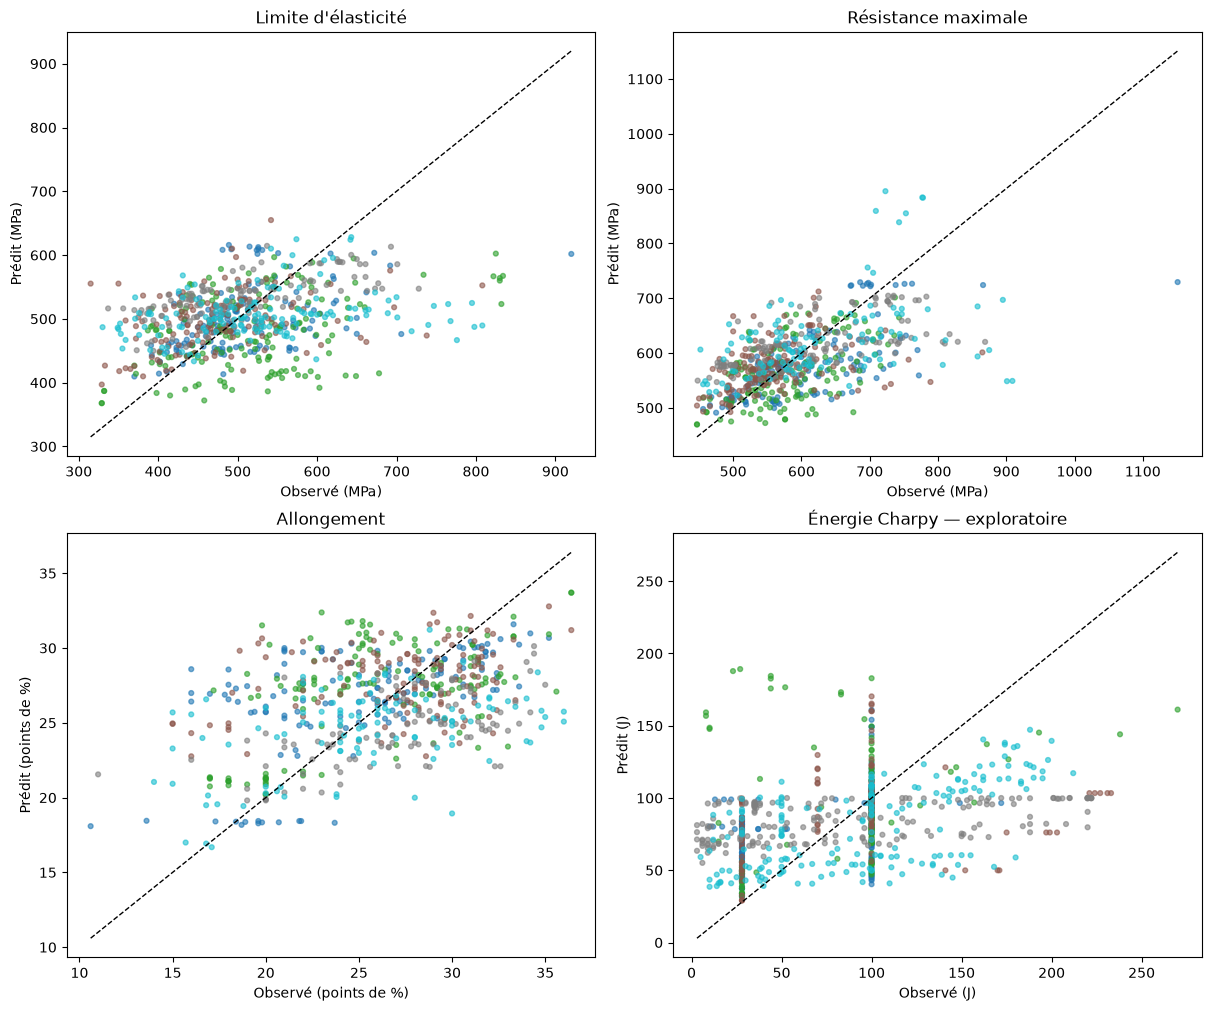

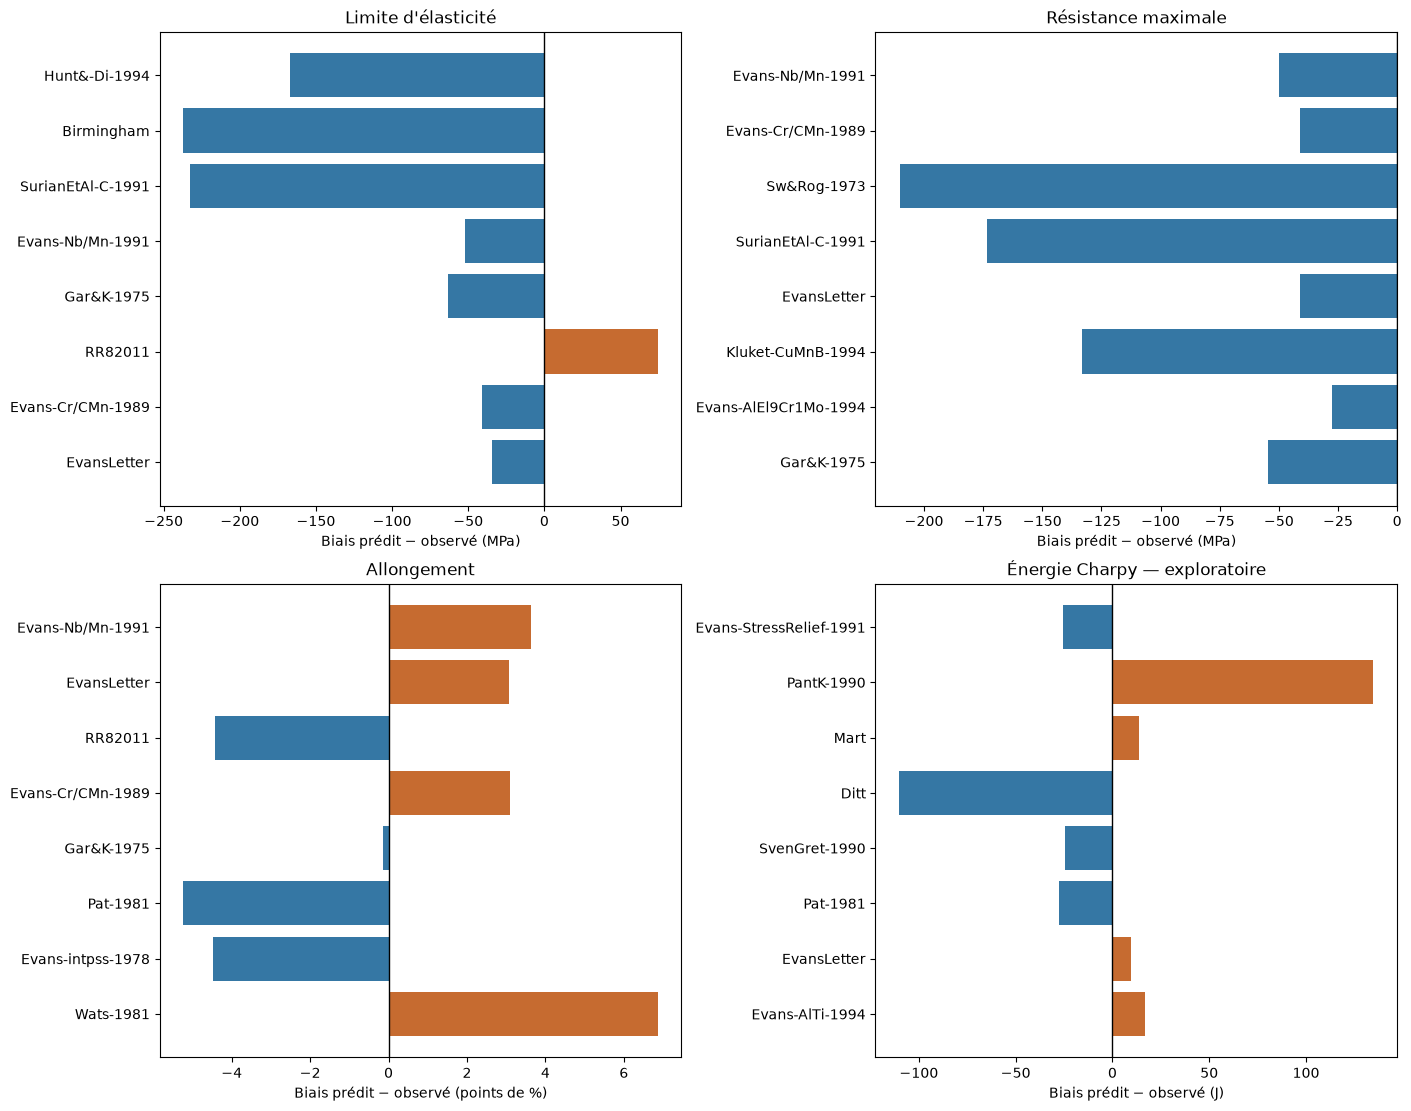

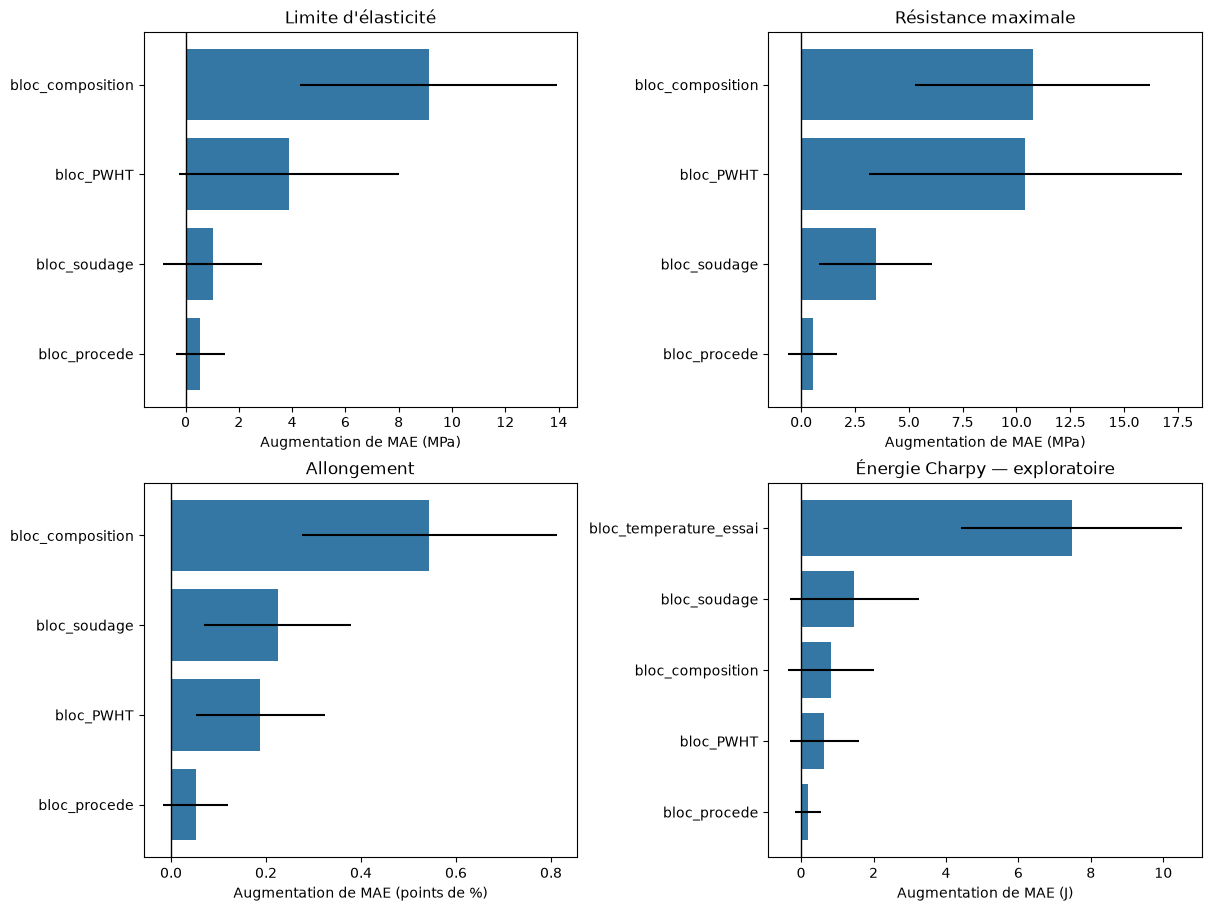

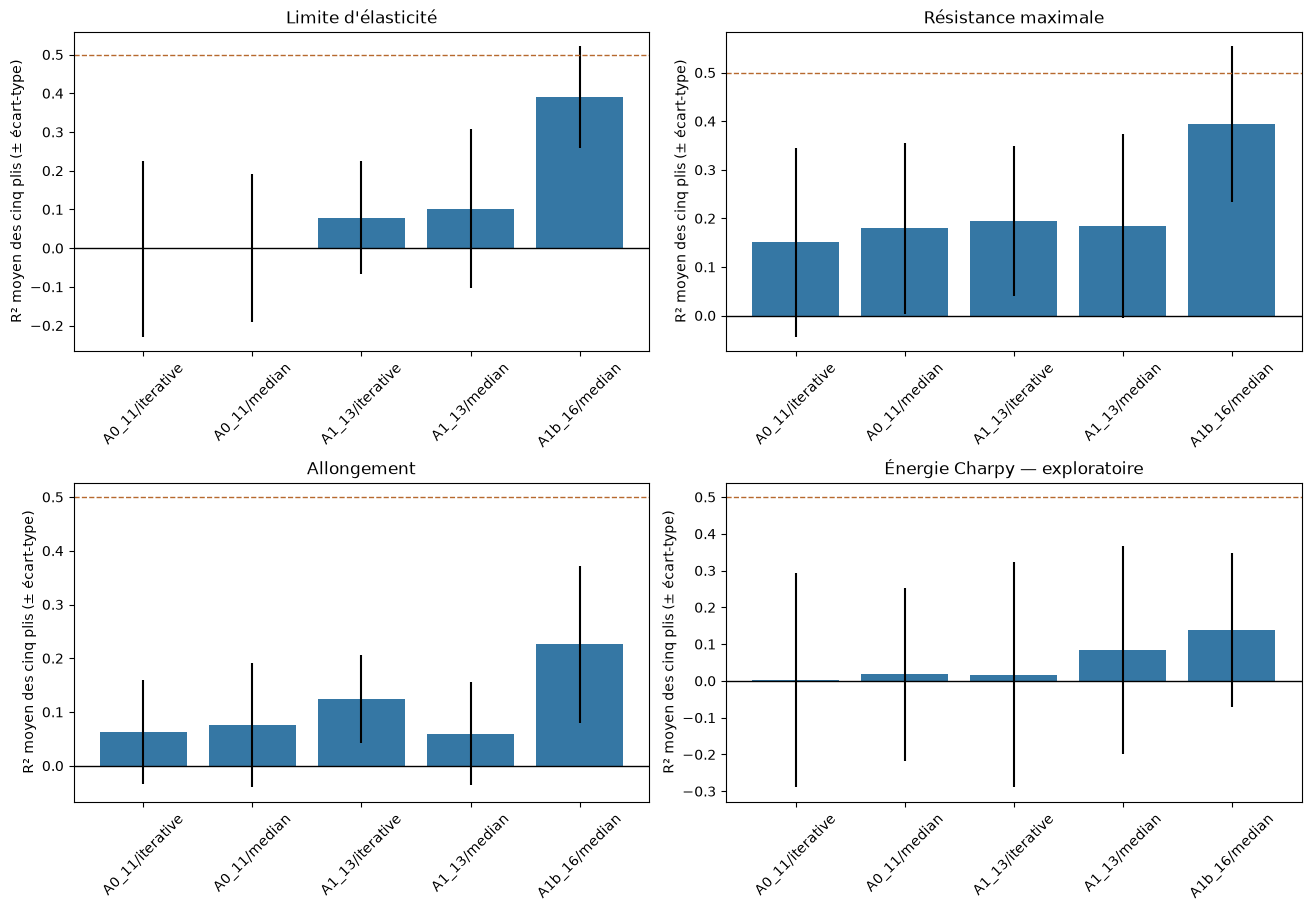

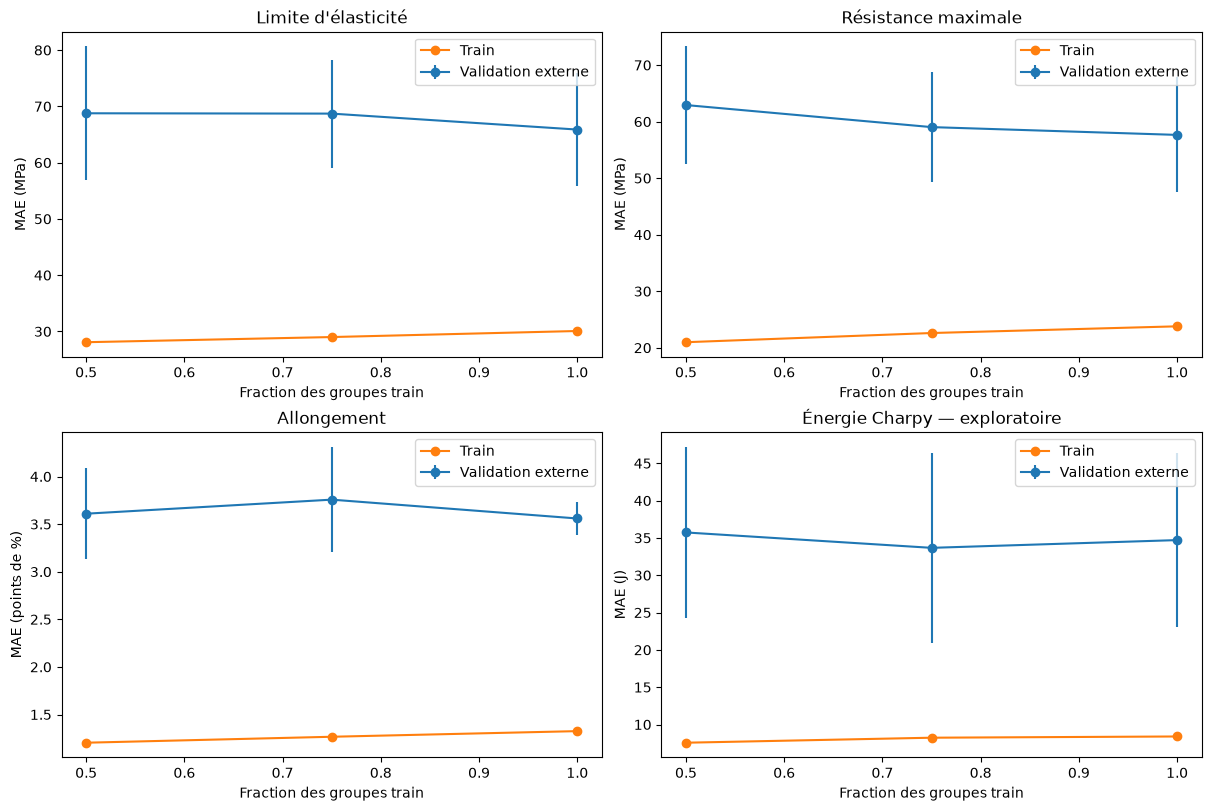

In [12]:
fig,axes=plt.subplots(2,2,figsize=(12,10),layout='constrained')
for ax,target in zip(axes.ravel(),TARGETS):
    g=domain.loc[domain.target==target]
    ax.scatter(g.y_true,g.y_pred,c=g.outer_fold,cmap='tab10',s=12,alpha=.6)
    lo=min(g.y_true.min(),g.y_pred.min()); hi=max(g.y_true.max(),g.y_pred.max())
    ax.plot([lo,hi],[lo,hi],'k--',lw=1)
    ax.set(title=TARGET_NAMES[target],xlabel=f'Observé ({TARGET_UNITS[target]})',ylabel=f'Prédit ({TARGET_UNITS[target]})')
fig.savefig(OUT/'observed_predicted.png',dpi=160); plt.show()
fig,axes=plt.subplots(2,2,figsize=(14,11),layout='constrained')
for ax,target in zip(axes.ravel(),TARGETS):
    g=group_errors.loc[(group_errors.target==target)&(group_errors.model=='random_forest')].nlargest(8,'SSE').sort_values('SSE')
    ax.barh(g.group,g.bias,color=np.where(g.bias>0,'#c66b30','#3577a4'))
    ax.axvline(0,color='black',lw=1); ax.set(title=TARGET_NAMES[target],xlabel=f'Biais prédit − observé ({TARGET_UNITS[target]})')
fig.savefig(OUT/'group_bias.png',dpi=160); plt.show()
fig,axes=plt.subplots(2,2,figsize=(12,9),layout='constrained')
for ax,target in zip(axes.ravel(),TARGETS):
    g=importance_summary.loc[(importance_summary.target==target)&(importance_summary.kind=='bloc')].sort_values('MAE_increase')
    ax.barh(g.feature,g.MAE_increase,xerr=g.repeat_fold_sd,color='#3577a4')
    ax.axvline(0,color='black',lw=1); ax.set(title=TARGET_NAMES[target],xlabel=f'Augmentation de MAE ({TARGET_UNITS[target]})')
fig.savefig(OUT/'block_importance.png',dpi=160); plt.show()
fig,axes=plt.subplots(2,2,figsize=(13,9),layout='constrained')
for ax,target in zip(axes.ravel(),TARGETS):
    g=summary.loc[(summary.target==target)&(summary.model=='random_forest')&(summary.folds==5)].copy()
    labels=g.feature_set+'/'+g.imputer
    ax.bar(labels,g.R2_mean,yerr=g.R2_sd,color='#3577a4')
    ax.axhline(0,color='black',lw=1); ax.axhline(.5,color='#b7692e',ls='--',lw=1)
    ax.tick_params(axis='x',rotation=45); ax.set(title=TARGET_NAMES[target],ylabel='R² moyen des cinq plis (± écart-type)')
fig.savefig(OUT/'rf_sensitivity.png',dpi=160); plt.show()
fig,axes=plt.subplots(2,2,figsize=(12,8),layout='constrained')
learning=pd.DataFrame(learning_rows)
for ax,target in zip(axes.ravel(),TARGETS):
    g=learning.loc[(learning.target==target)&(learning.status=='ok')].groupby('fraction').agg(MAE=('MAE','mean'),sd=('MAE','std'),train_MAE=('train_MAE','mean'))
    ax.errorbar(g.index,g.MAE,yerr=g.sd,marker='o',label='Validation externe')
    ax.plot(g.index,g.train_MAE,marker='o',label='Train'); ax.legend()
    ax.set(title=TARGET_NAMES[target],xlabel='Fraction des groupes train',ylabel=f'MAE ({TARGET_UNITS[target]})')
fig.savefig(OUT/'learning_curves.png',dpi=160); plt.show()

## Ce que les calculs permettent de conclure

R² ci-dessous = **moyenne des cinq plis externes**, même cohorte et mêmes splits.
Le RF 16/médiane est une comparaison descriptive ; la sélection conjointe choisit
schéma/imputation/famille/paramètres uniquement sur MAE interne.

| Cible | R² RF 13/itérative | R² RF 16/médiane | R² sélection conjointe interne | MAE RF 16/médiane |
| --- | --- | --- | --- | --- |
| `yield_strength` | 0.079 | 0.390 | 0.337 | 54.14 |
| `uts` | 0.194 | 0.394 | 0.334 | 48.91 |
| `elongation` | 0.125 | 0.226 | 0.164 | 3.34 |
| `charpy_J` | 0.017 | 0.138 | -0.100 | 33.03 |

- Le partage aléatoire des lignes donne ≈0,55/0,62/0,53/0,77 avec le même RF
  fixe : presque toutes les séries de validation sont présentes dans le train.
  Le partage par groupes mesure le transfert à des séries inédites, plus difficile.
- À médiane identique, Ni/Cr/Mo réduisent la MAE RF de 11,06 MPa (YS) et
  8,80 MPa (UTS), avec intervalles du bootstrap par groupes positifs. Pour
  allongement/Charpy, les intervalles du gain d'extension incluent zéro.
- L'itérative à 16 entrées échoue dans 11 contextes cible/pli ; aucun des cinq
  plis Charpy n'est disponible dans ce scénario. 436 évaluations réussies sur
  480 prévues ; les 44 indisponibles sont documentées, sans remplacement implicite.
- Les contributions locales expliquent le calcul ; les biais par groupe et
  les domaines X étayent les difficultés de transfert. Aucune cause physique
  isolée ni plafond irréductible R²<0,5 n'est démontré.
- Charpy garde une forte incertitude de protocole : deux séries E(T) confirmées,
  une extraction T100 étayée, 21 séries non résolues. La sélection conjointe
  interne reste faible ; choisir le meilleur score externe serait optimiste.

Suite étayée : valider un candidat 16/médiane pour la traction sur de nouvelles
séries indépendantes, poursuivre la correspondance des sources et la qualité des
entrées pour Charpy. Le benchmark 03 est conservé et COREG reste différé.


## Traçabilité et conclusion scientifique

Les conclusions chiffrées et les causes étayées sont consignées dans
`reports/11_performance_diagnostics.md`. Les hypothèses non identifiées restent
explicitement ouvertes. Les séries difficiles ne sont pas supprimées pour
augmenter R². Ni les importances ni l'ACP ne prouvent que la cible est prédictible
avec les entrées disponibles. Une nouvelle validation indépendante sera nécessaire
après un choix scientifique résultant de cette investigation.

In [14]:
# Source audit versions and hashes; no trained model serialized.
source_hashes={p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in (OUT/'sources').glob('*.pdf')}
nb_source=json.loads((PROJECT_ROOT/'notebooks/04_diagnostics.ipynb').read_text())
source_text='\n\n'.join(''.join(c['source']) for c in nb_source['cells'])
manifest={'protocol_version':'salh-diagnostics-v1','seed':SEED,'bootstrap_repeats':BOOTSTRAP_REPEATS,
    'permutation_repeats':PERMUTATION_REPEATS,'elapsed_seconds':(json.loads((OUT/'manifest.json').read_text())['elapsed_seconds']
       if globals().get('REFRESH_EXISTING_RESULTS',False) else time.perf_counter()-STARTED),
    'supplementary_refresh_seconds':time.perf_counter()-STARTED if globals().get('REFRESH_EXISTING_RESULTS',False) else 0,
    'raw_sha256':preparation_manifest['raw_sha256'],
    'reference_manifest_sha256':hashlib.sha256((REFERENCE/'manifest.json').read_bytes()).hexdigest(),
    'notebook_source_sha256':hashlib.sha256(source_text.encode()).hexdigest(),
    'feature_sets':FEATURE_SETS,'imputers':IMPUTERS,'families':FAMILIES,'grids':PARAM_GRIDS,
    'cohort':'same strict13 population, target-specific eligibility; no additional filter for 16 features',
    'splits':'unchanged exported 5 outer / 3 inner group folds',
    'selection':'mean inner MAE; secondary mean inner MSE on primary configuration',
    'joint_selection':'feature set, imputation, family and parameters selected by inner MAE only',
    'interpretation':'retrospective diagnostics; no fresh independent test set',
    'preflight_failures':len(pd.read_csv(OUT/'sensitivity_failures.csv')),
    'outer_evaluations_expected':480,
    'outer_evaluations_completed':len(pd.read_csv(OUT/'sensitivity_outer_metrics.csv')),
    'split_control_parameters':SPLIT_RF_PARAMS,
    'local_explanation':'exact order-dependent forest path contributions, not SHAP or causal',
    'masked_reconstruction':'20% of observed Ni/Cr/Mo entries; same masks; paired successful contexts only',
    'charpy_source_coverage':{'confirmed_E_T_groups':2,'confirmed_E_T_rows':174,
                           'source_matched_threshold_inference_groups':1,'unresolved_groups':21},
    'versions':{'python':platform.python_version(),'sklearn':sklearn.__version__,'pandas':pd.__version__,'numpy':np.__version__},
    'source_pdf_sha256':source_hashes,
    'files':{p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in OUT.glob('*.csv')}}
(OUT/'manifest.json').write_text(json.dumps(manifest,indent=2,ensure_ascii=False)+'\n')
display(pd.Series({k:manifest[k] for k in ['elapsed_seconds','preflight_failures','outer_evaluations_completed']}))

elapsed_seconds                2218.887353
preflight_failures               11.000000
outer_evaluations_completed     436.000000
dtype: float64